<img src="https://drive.google.com/uc?export=view&id=1KaYghV3gYDHexZNrY_5toaKYBjbokXcO" width="500" alt="Mi imagen" />



# **Módulo IV - Lab 2: Aprendizaje No Supervisado**
## Dataset: Wisconsin Breast Cancer
---

**Pregunta central de este lab:**
> *¿Puede un algoritmo, sin conocer los diagnósticos, separar tumores malignos de benignos
> basándose únicamente en mediciones morfológicas de las células?*

---

**Contenidos:**
1. Contexto clínico y descripción del dataset
2. Análisis exploratorio (EDA)
3. Preprocesamiento: estandarización y PCA
4. K-Means Clustering
5. Clustering Jerárquico
6. DBSCAN
7. Comparación de métricas y conclusiones

Para modelar la respuesta de clasificacion es necesario usar ANS, el cual no se le da las etiquetas de salida, en este caso maligno o benigno.
El ANS buscar funciones que calculen el centroide de medias, varianza y covarianza de los datos. En base a ellos busca grupos que tengan maximize
la homogeneidad interna (dentro de grupos, mayor varianza) y maximizen las diferencias entre grupos (menor covarianza). La forma en que incluye un dato en el grupo es que tan lejos esta la distancia al cuadrado al centroide.

## 0. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    confusion_matrix
)
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')
print('Librerías cargadas.')

Librerías cargadas.


## 1. Contexto y Descripción del Dataset

### ¿Qué es la FNA?
La **aspiración con aguja fina (*Fine Needle Aspiration*, FNA)** es un procedimiento diagnóstico
mínimamente invasivo. Se inserta una aguja delgada en una masa mamaria sospechosa y se extrae
una muestra de células que luego se analiza al microscopio.

El Dr. William Wolberg (Universidad de Wisconsin, 1993) digitalizó imágenes de estas muestras
y midió características geométricas de los **núcleos celulares** visibles.

### ¿Por qué los núcleos?
En patología, las células malignas muestran **núcleos más grandes, irregulares y asimétricos**
que las benignas. Estas diferencias morfológicas son la base del diagnóstico histológico clásico.

### Estructura del dataset
- **569 pacientes** con masa mamaria sospechosa
- **30 variables numéricas** derivadas de imágenes microscópicas
- **Diagnóstico:** Maligno (M) o Benigno (B) - confirmado por biopsia


Las 30 variables se construyen a partir de **10 características base**, cada una resumida en 3 estadísticas:

| Característica | Descripción clínica |
|---|---|
| radius | Radio medio de los núcleos celulares |
| texture | Variación en la escala de grises (heterogeneidad) |
| perimeter | Perímetro del núcleo |
| area | Área del núcleo |
| smoothness | Regularidad del contorno |
| compactness | Relación perímetro²/área (forma circular vs irregular) |
| concavity | Profundidad de las indentaciones del contorno |
| concave points | Número de indentaciones cóncavas |
| symmetry | Simetría del núcleo |
| fractal dimension | Complejidad del contorno (dimensión fractal) |

Para cada una: `_mean` (media), `_se` (error estándar), `_worst` (valor máximo de los 3 núcleos más grandes).

> ### 📌 **¿Por qué usamos este dataset?**
> Los tumores malignos
> tienen células morfológicamente distintas. Lo que haremos aquí es ver si los algoritmos
> pueden *descubrir* esa distinción sin que nadie les diga cuál es cuál.

### 💬 Antes de ver los datos:

  1. ¿Qué características morfológicas esperarían que sean más distintas entre tumores malignos y benignos?

  2. ¿Sería posible separar los dos grupos solo con mediciones geométricas de los núcleos?

  3. ¿Qué limitaciones tendría usar este tipo de modelo?

  4. ¿Por qué sería útil usar ML en lugar de realozar una biopsia, por ejemplo, y confimar el diagnóstico?

RESPUESTAS:
1. Nucleos hipertrofiados, asimetria, mayor concavidad y convexidad, mayor dimension fractal
2. La separacion en 2 grupos seria un aproximacion, con cierto margen de error. Tambien depende si son variable medicamente validas
3. Limitaciones incluyen datos similares entre malingos y sanos, que no necesariamente pueden separarse linealmente. Es decir, la zona gris del dataset.
4. Porque es un metodo no invasivo, y puede ser un diagnostico previo que luego el medico seleccione los verdaderos positivos y realize una biopsia

## 2. Análisis Exploratorio de Datos (EDA)

### 2.1 Distribución general de cada variable


In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
# Cargar el dataset
bc = load_breast_cancer()

# Crear un DataFrame para exploración
df = pd.DataFrame(bc.data, columns=bc.feature_names)
df['diagnosis'] = bc.target          # 0 = maligno, 1 = benigno
df['diagnosis_label'] = df['diagnosis'].map({0: 'Maligno', 1: 'Benigno'})

# X e y para los modelos (sin la columna de diagnóstico)
X = bc.data
y = bc.target       # 0=maligno, 1=benigno
y_label = np.where(y == 0, 'Maligno', 'Benigno')

mean_cols = [c for c in bc.feature_names if 'mean' in c]

print('=== ESTRUCTURA DEL DATASET ===')
print(f'Observaciones: {X.shape[0]}')
print(f'Variables:     {X.shape[1]}')
print()

=== ESTRUCTURA DEL DATASET ===
Observaciones: 569
Variables:     30



In [3]:
print(bc.DESCR)


.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

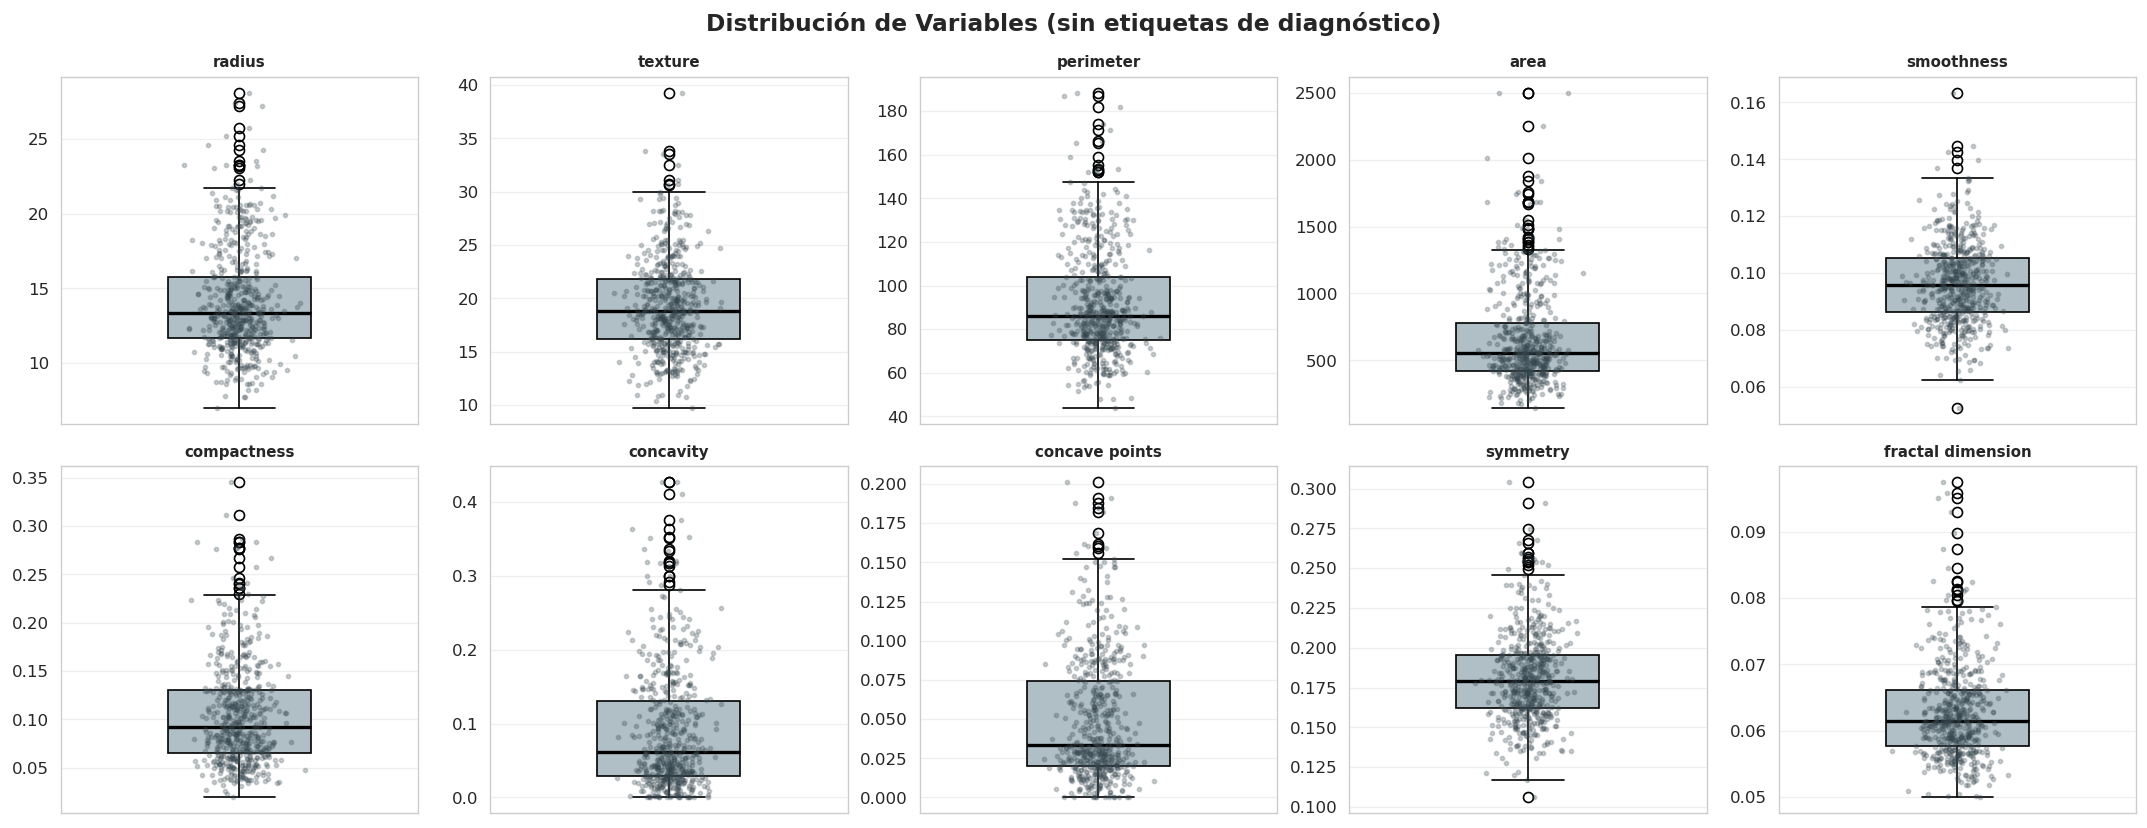

Cada punto es un paciente. ¿Ven algo inusual en alguna variable?


In [4]:
# Usamos las 10 variables _mean (las más interpretables)
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle('Distribución de Variables (sin etiquetas de diagnóstico)',
             fontsize=14, fontweight='bold')

for ax, var in zip(axes.flatten(), mean_cols):
    vals = df[var]

    # Boxplot
    bp = ax.boxplot(vals, patch_artist=True,
                    medianprops=dict(color='black', linewidth=2),
                    widths=0.4)
    bp['boxes'][0].set_facecolor('#B0BEC5')   # gris neutro

    # Puntos individuales
    ax.scatter(np.random.normal(1, 0.05, size=len(vals)),
               vals, alpha=0.25, s=6, color='#37474F', zorder=3)

    # Nombre legible
    nombre = var.replace('mean ', '')
    ax.set_title(nombre, fontweight='bold', fontsize=9)
    ax.set_xticks([])
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
print('Cada punto es un paciente. ¿Ven algo inusual en alguna variable?')

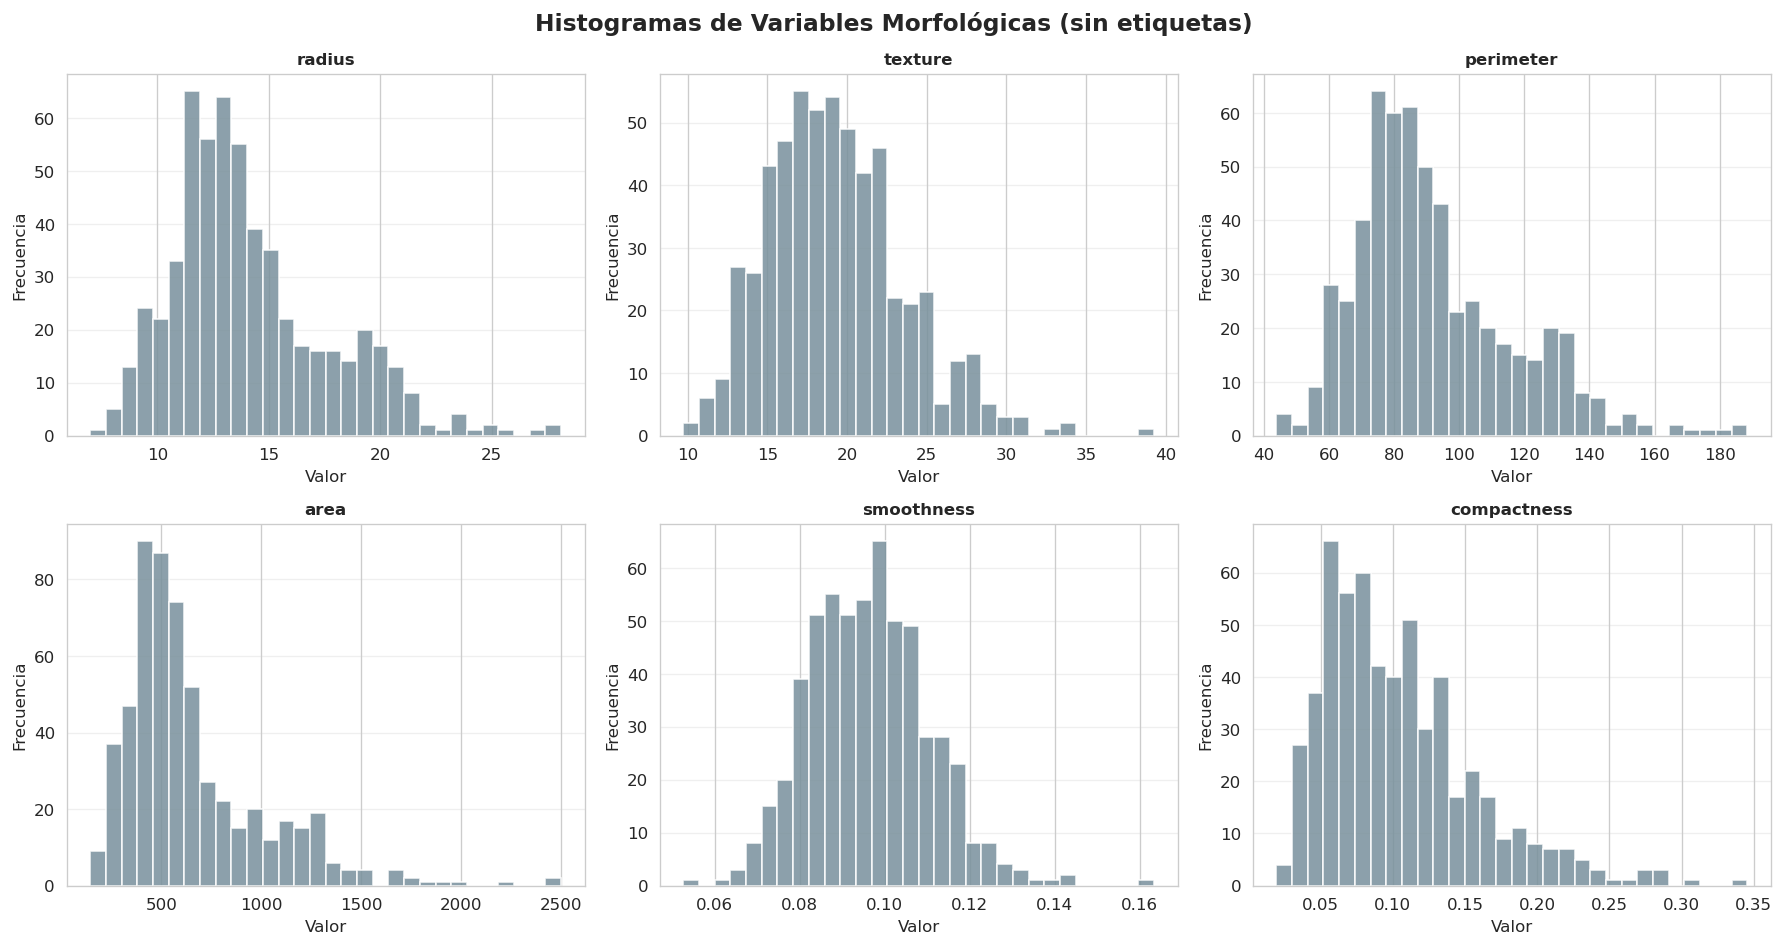

Observa la forma de cada histograma.
¿Alguno sugiere que podría haber dos subpoblaciones mezcladas?


In [4]:
# Histogramas de las 6 variables más relevantes
vars_hist = mean_cols[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Histogramas de Variables Morfológicas (sin etiquetas)',
             fontsize=14, fontweight='bold')

for ax, var in zip(axes.flatten(), vars_hist):
    ax.hist(df[var], bins=30, color='#78909C', edgecolor='white', alpha=0.85)
    nombre = var.replace('mean ', '')
    ax.set_title(nombre, fontweight='bold', fontsize=10)
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
print('Observa la forma de cada histograma.')
print('¿Alguno sugiere que podría haber dos subpoblaciones mezcladas?')

<Figure size 1440x1200 with 0 Axes>

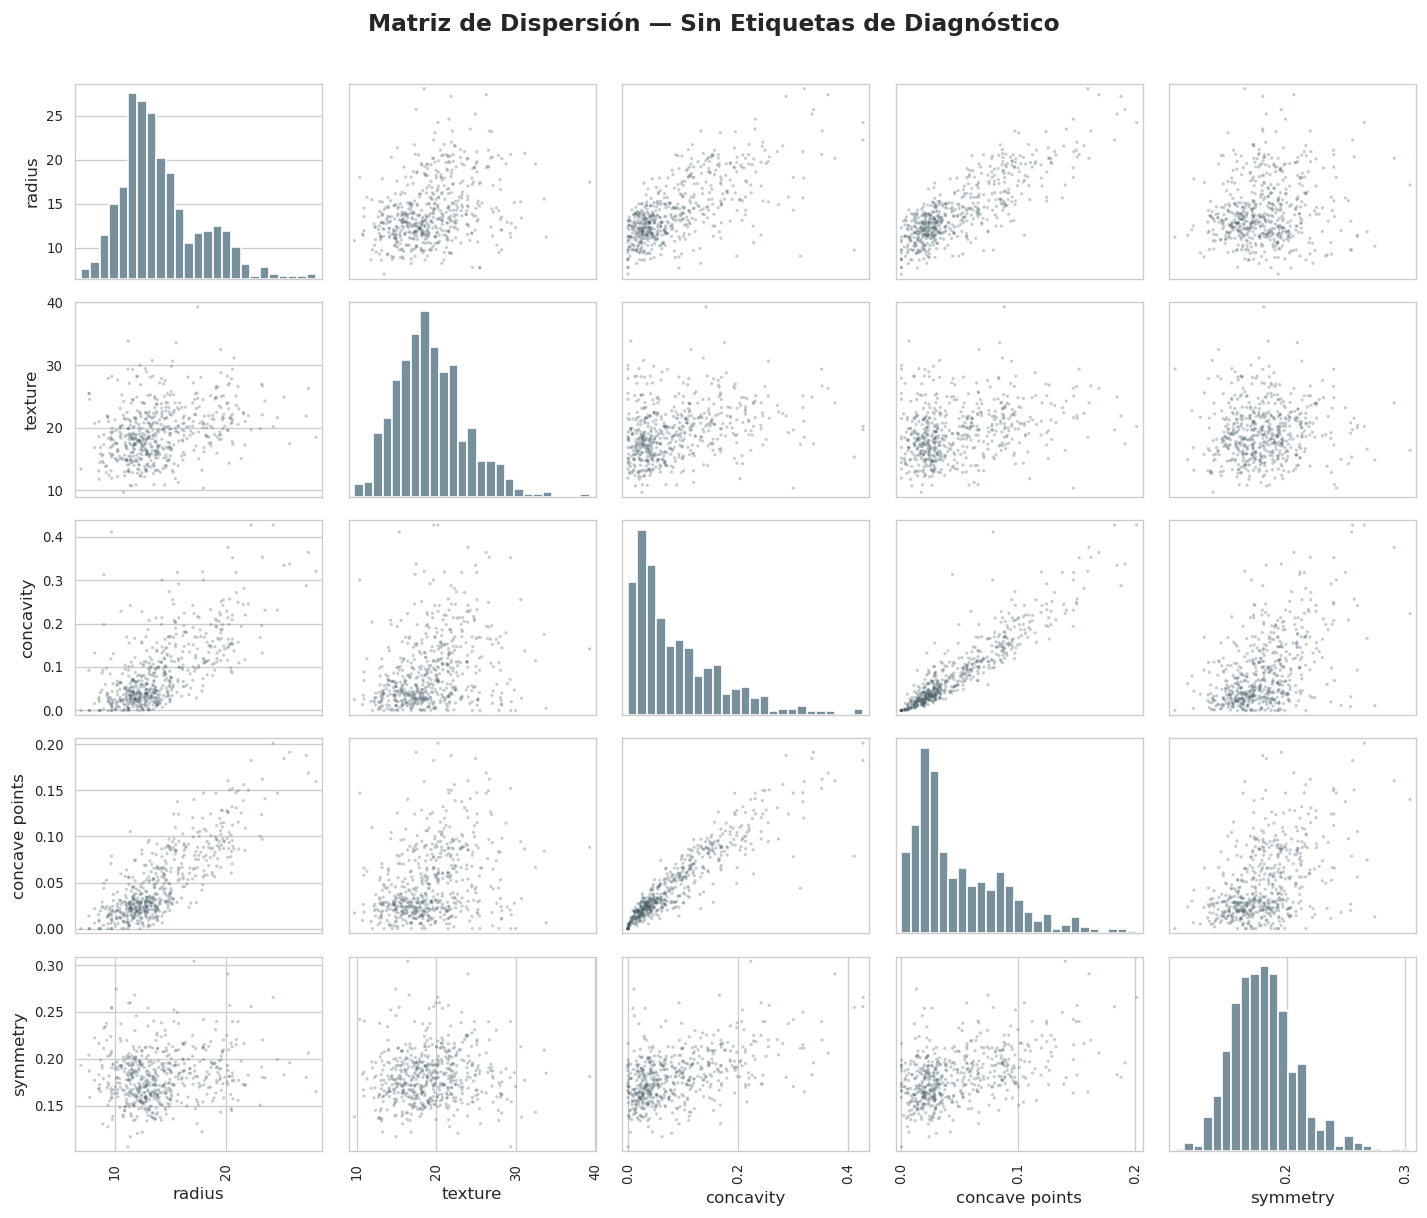

Cada punto es un paciente.
¿Ven alguna separación natural en alguno de estos gráficos?


In [5]:
# Scatter matrix
# Usamos 5 variables para que el gráfico sea legible
vars_scatter = [
    'mean radius',
    'mean texture',
    'mean concavity',
    'mean concave points',
    'mean symmetry'
]

df_scatter = df[vars_scatter].copy()
# Nombres más cortos para el gráfico
df_scatter.columns = [c.replace('mean ', '') for c in vars_scatter]

fig = plt.figure(figsize=(12, 10))
axes = pd.plotting.scatter_matrix(
    df_scatter,
    figsize=(12, 10),
    alpha=0.3,
    s=15,
    color='#455A64',
    diagonal='hist',
    hist_kwds={'bins': 25, 'color': '#78909C', 'edgecolor': 'white'}
)

# Titulo general
plt.suptitle('Matriz de Dispersión — Sin Etiquetas de Diagnóstico',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
print('Cada punto es un paciente.')
print('¿Ven alguna separación natural en alguno de estos gráficos?')

### 💬 Antes de seguir:

1. Mirando los histogramas, ¿alguna variable les parece bimodal?
   ¿Qué implicaría bimodalidad en este contexto?
2. En la scatter matrix, ¿qué par de variables tiene la correlación más visual?
   ¿Ven alguna separación entre grupos sin saber los diagnósticos?
3. Si tuviesen que elegir **una sola variable** para intentar separar dos grupos,
   ¿cuál elegirían? ¿Por qué?


1. Los histogramas de radius, concavidad, textura y perimetro tendrian un patron bimodal, lo que podria indicar 2 grupos de datos dentro de la variable
2. Los pares de variables con una correlacion aparente son concavidad-simetria, concave points-cancivity y radius, concavity-radius.
3. Elijiria concavity, ya que tanto el histograma bimodal y matriz de dispersion estan mostrando dos grupos de datos. 

### 2.1 Distribución de las variables teniendo en cuenta en diagnóstico

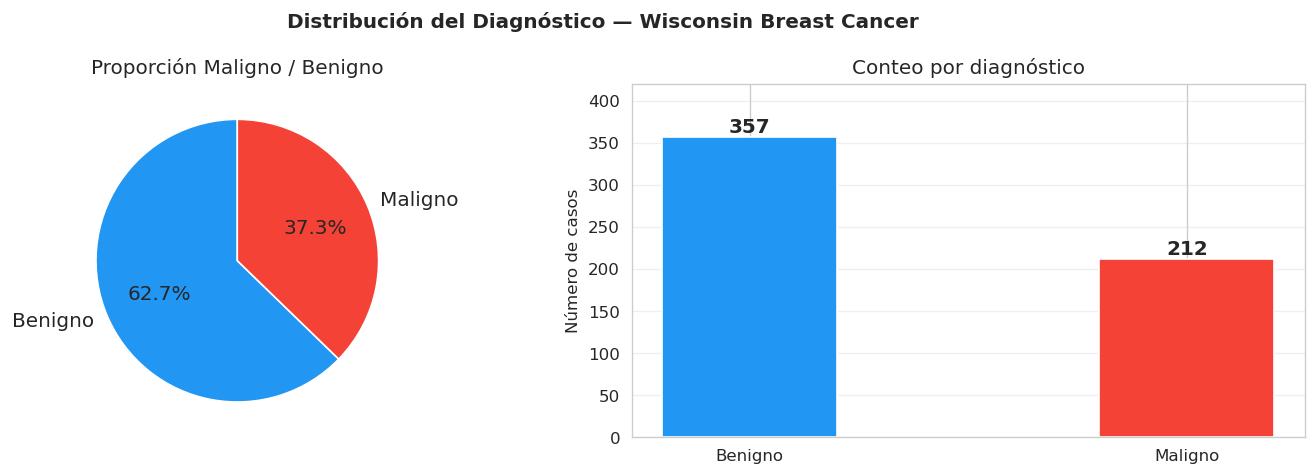

In [6]:
# Distribución del diagnóstico
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Distribución del Diagnóstico — Wisconsin Breast Cancer', fontweight='bold')

colores_diag = {'Benigno': '#2196F3', 'Maligno': '#F44336'}

# Pie chart
ax = axes[0]
conteo_vals = df['diagnosis_label'].value_counts()
ax.pie(conteo_vals, labels=conteo_vals.index,
       colors=[colores_diag[l] for l in conteo_vals.index],
       autopct='%1.1f%%', startangle=90,
       textprops={'fontsize': 12})
ax.set_title('Proporción Maligno / Benigno')

# Barras
ax = axes[1]
bars = ax.bar(conteo_vals.index, conteo_vals.values,
              color=[colores_diag[l] for l in conteo_vals.index],
              edgecolor='white', width=0.4)
for bar, val in zip(bars, conteo_vals.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(val), ha='center', fontsize=12, fontweight='bold')
ax.set_ylabel('Número de casos')
ax.set_title('Conteo por diagnóstico')
ax.set_ylim(0, 420)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

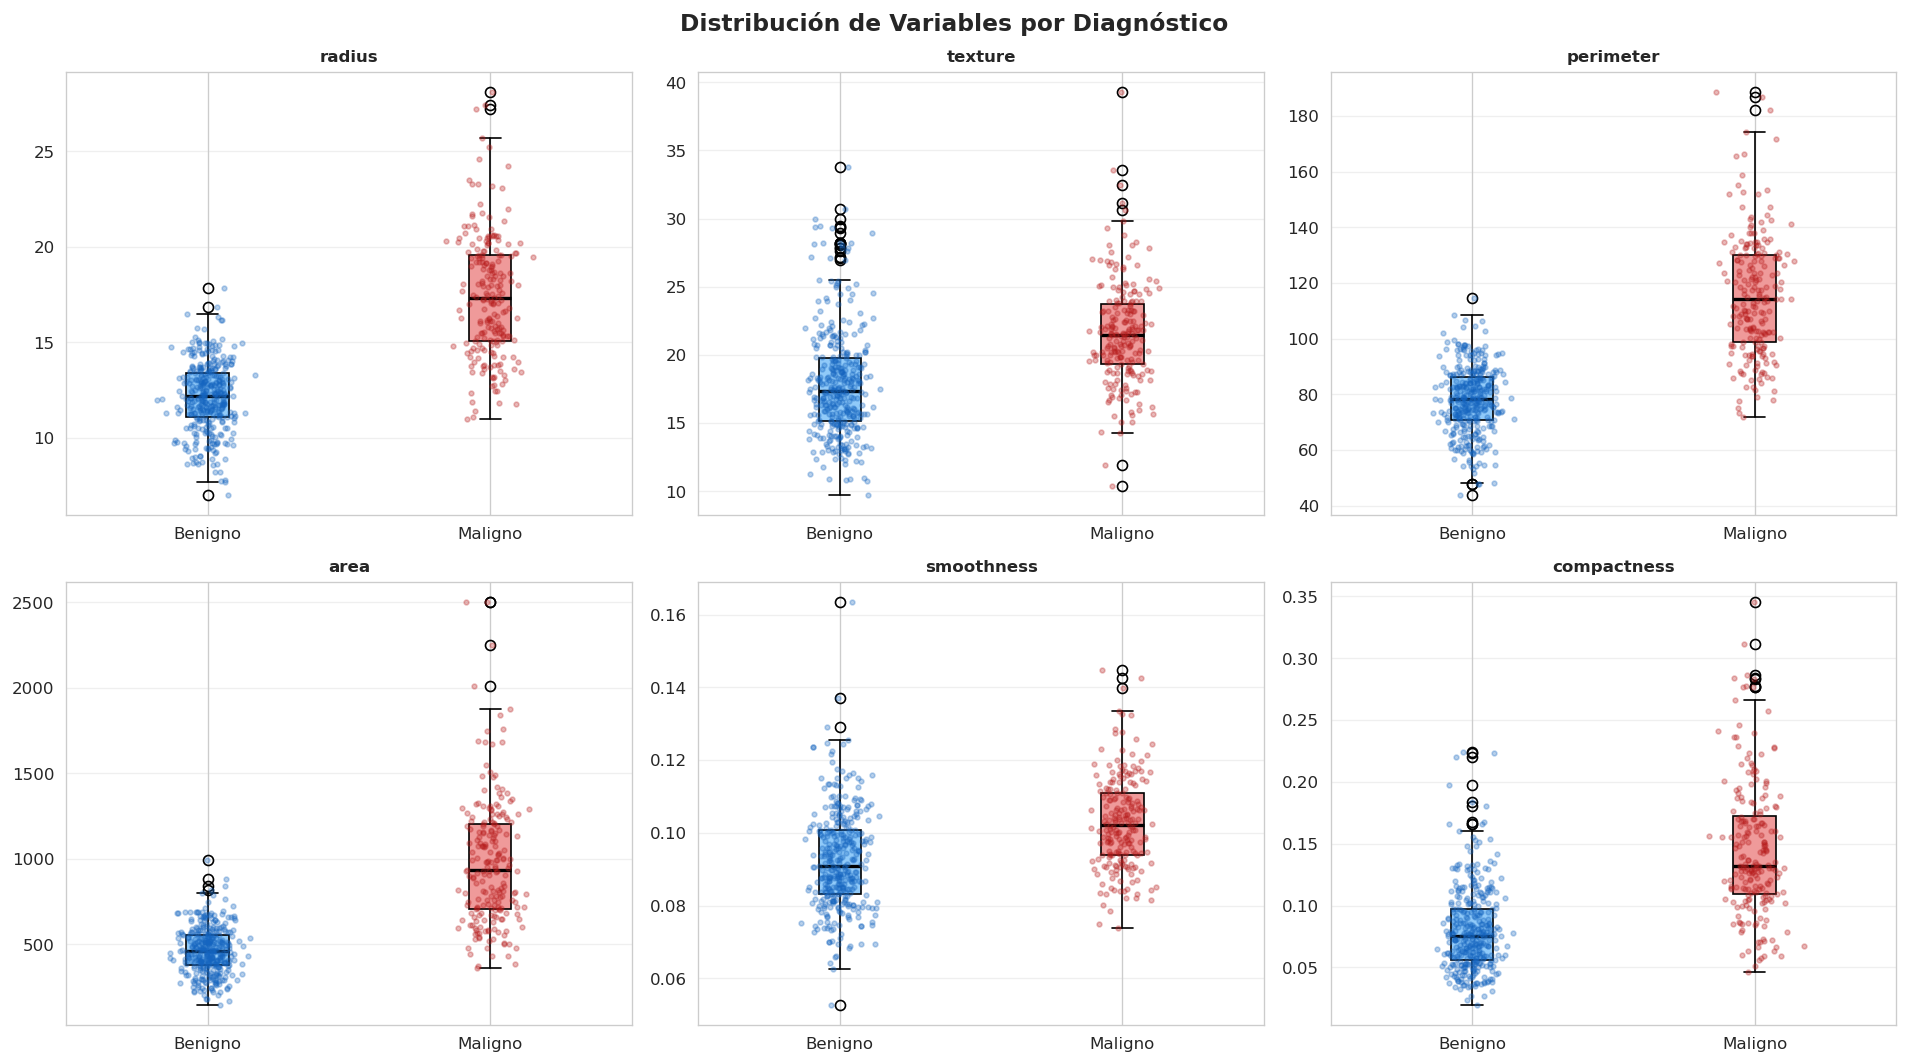

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Distribución de Variables por Diagnóstico',
             fontsize=14, fontweight='bold')

for ax, var in zip(axes.flatten(), mean_cols[:6]):
    data_b = df[df['diagnosis_label'] == 'Benigno'][var]
    data_m = df[df['diagnosis_label'] == 'Maligno'][var]

    bp = ax.boxplot([data_b, data_m],
                    tick_labels=['Benigno', 'Maligno'],
                    patch_artist=True,
                    medianprops=dict(color='black', linewidth=2))

    bp['boxes'][0].set_facecolor('#90CAF9')   # azul claro = benigno
    bp['boxes'][1].set_facecolor('#EF9A9A')   # rojo claro  = maligno

    for i, (data, color) in enumerate(
            [(data_b, '#1565C0'), (data_m, '#B71C1C')], 1):
        ax.scatter(np.random.normal(i, 0.05, size=len(data)),
                   data, alpha=0.3, s=8, color=color, zorder=3)

    nombre = var.replace('mean ', '')
    ax.set_title(nombre, fontweight='bold', fontsize=10)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

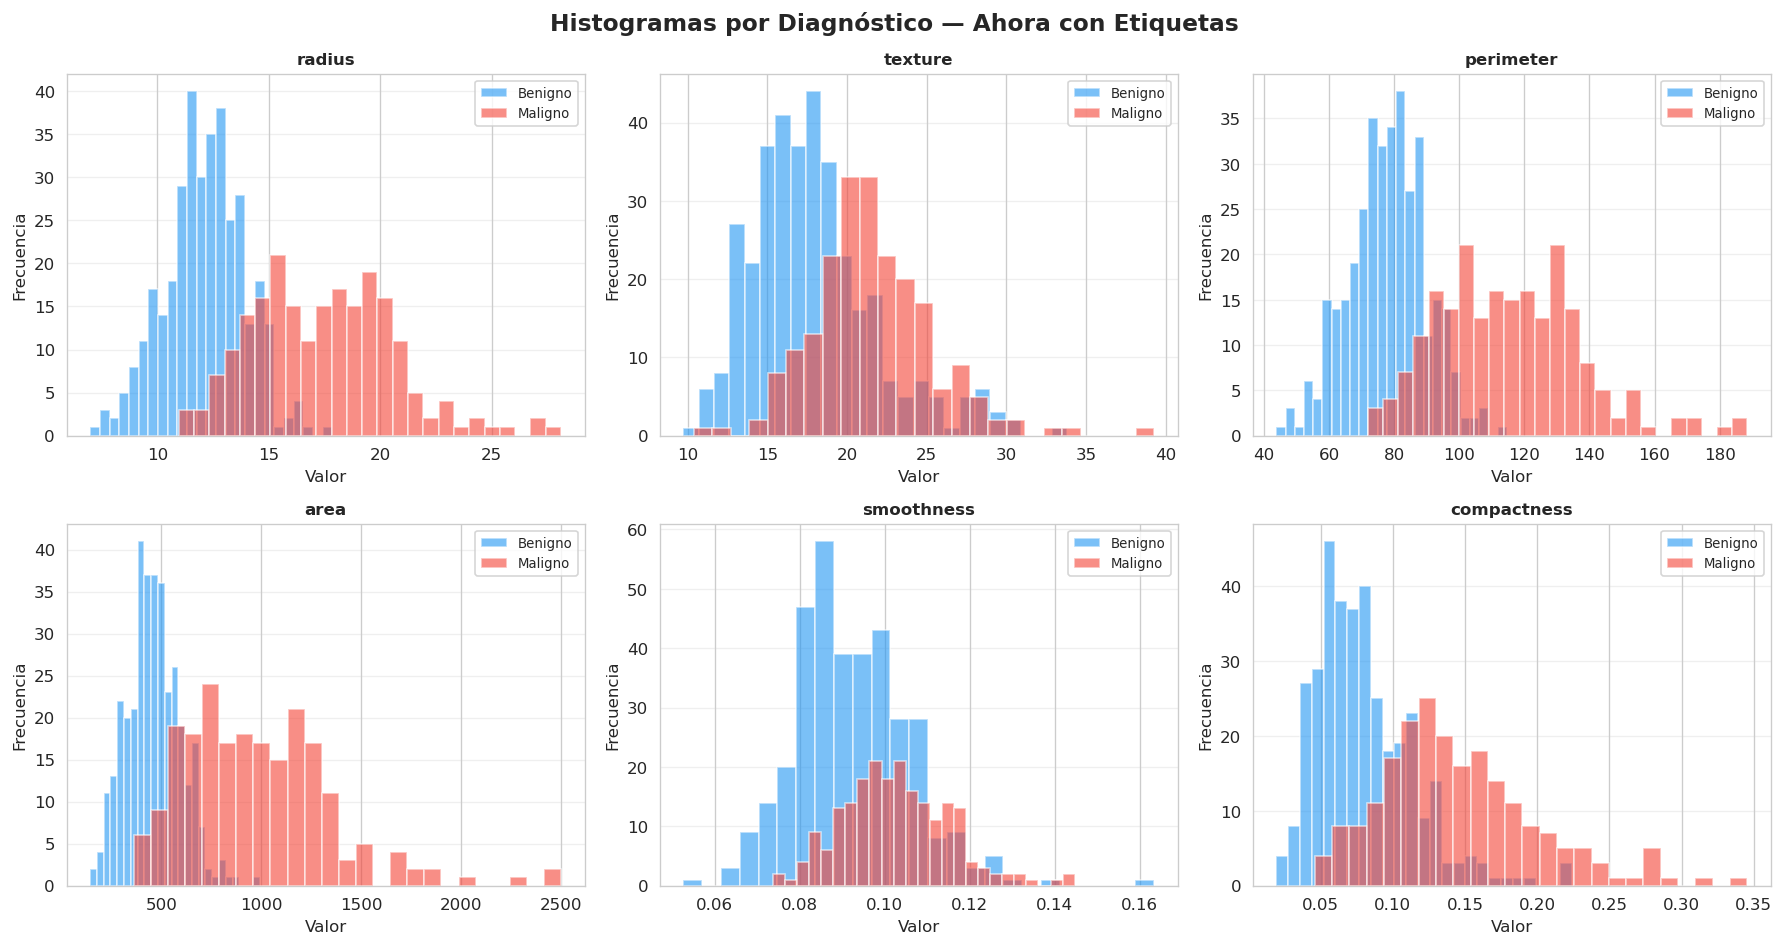

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Histogramas por Diagnóstico — Ahora con Etiquetas',
             fontsize=14, fontweight='bold')

for ax, var in zip(axes.flatten(), mean_cols[:6]):
    data_b = df[df['diagnosis_label'] == 'Benigno'][var]
    data_m = df[df['diagnosis_label'] == 'Maligno'][var]

    # Superponer histogramas con transparencia
    ax.hist(data_b, bins=25, color='#2196F3', alpha=0.6,
            edgecolor='white', label='Benigno')
    ax.hist(data_m, bins=25, color='#F44336', alpha=0.6,
            edgecolor='white', label='Maligno')

    nombre = var.replace('mean ', '')
    ax.set_title(nombre, fontweight='bold', fontsize=10)
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

En los histogramas ponderados por etiquetas se puede ver que hay variables con buena separacion (ej. area, compactness) y otras que no, tienen demasiado solapamiento y no serian utiles para diagnosticar el tumor 

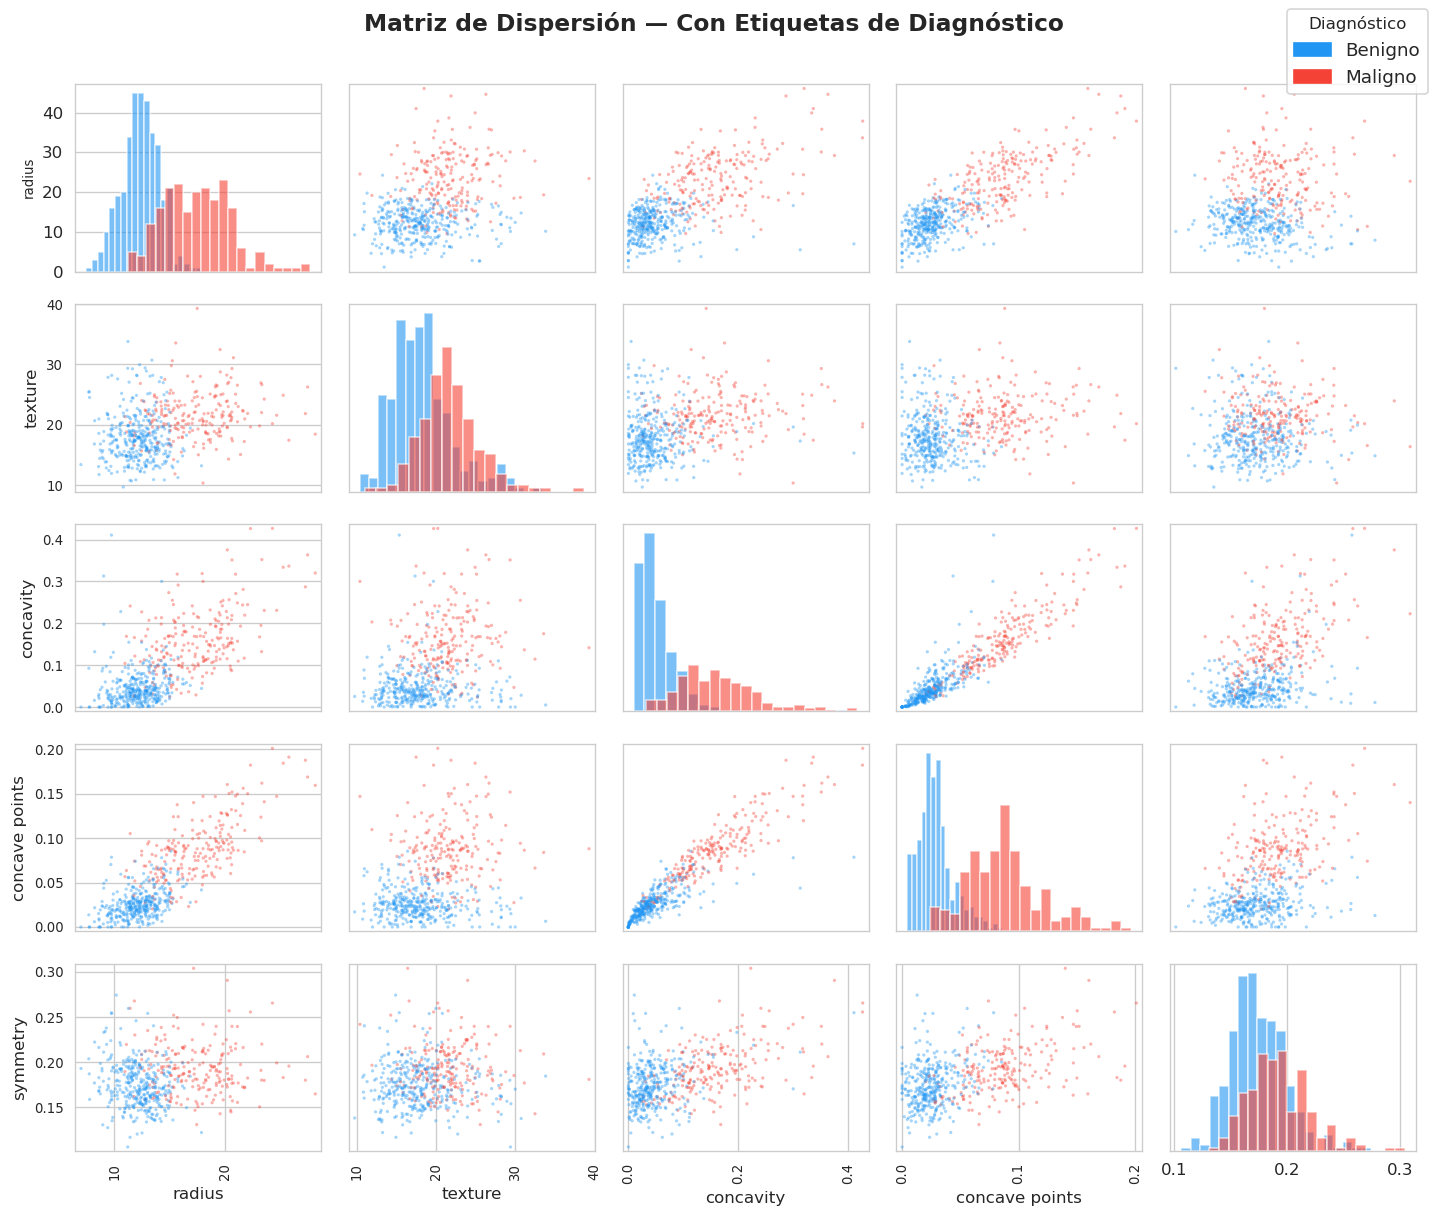

In [9]:
# Scatter matrix coloreada por diagnóstico
vars_scatter = [
    'mean radius',
    'mean texture',
    'mean concavity',
    'mean concave points',
    'mean symmetry'
]

df_scatter = df[vars_scatter + ['diagnosis_label']].copy()
df_scatter.columns = [c.replace('mean ', '') for c in vars_scatter] + ['diagnosis']

colores_puntos = df_scatter['diagnosis'].map(
    {'Benigno': '#2196F3', 'Maligno': '#F44336'}
).values

axes = pd.plotting.scatter_matrix(
    df_scatter.drop(columns='diagnosis'),
    figsize=(12, 10),
    alpha=0.4,
    s=15,
    color=colores_puntos,
    diagonal='hist',
    hist_kwds={'bins': 25, 'edgecolor': 'white'}
)

# Colorear histogramas de la diagonal por diagnóstico
for i, ax in enumerate(axes.diagonal()):
    ax.cla()
    var_orig = vars_scatter[i]
    nombre   = var_orig.replace('mean ', '')
    ax.hist(df[df['diagnosis_label'] == 'Benigno'][var_orig],
            bins=20, color='#2196F3', alpha=0.6, edgecolor='white')
    ax.hist(df[df['diagnosis_label'] == 'Maligno'][var_orig],
            bins=20, color='#F44336', alpha=0.6, edgecolor='white')
    ax.set_ylabel(nombre, fontsize=8)

# Leyenda manual
import matplotlib.patches as mpatches
leyenda = [
    mpatches.Patch(color='#2196F3', label='Benigno'),
    mpatches.Patch(color='#F44336', label='Maligno')
]
plt.gcf().legend(handles=leyenda, loc='upper right',
                 fontsize=11, title='Diagnóstico')
plt.suptitle('Matriz de Dispersión — Con Etiquetas de Diagnóstico',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Las matrices de dispersion son utiles para ver la variacion de las etiquetas. Como veiamos en los histogramas, hay variables con muchos datos solapantes que no hay modelo alguno que pueda separarlos, estan dentro del hiperplano de separacion o cerca del centroide. Sin embargo, variables como concave points y concavity que se nota separacion en las nubes de puntos y puede usarse para generar el ANS.

In [10]:
# Estadísticas descriptivas por grupo
# Nos enfocamos en las 10 variables 'mean'
mean_cols = [c for c in bc.feature_names if 'mean' in c]

desc = df.groupby('diagnosis_label')[mean_cols].mean().T
desc.columns.name = None
desc['diferencia_%'] = ((desc['Maligno'] - desc['Benigno']) / desc['Benigno'] * 100).round(1)
desc = desc.round(3)

print('Promedio por grupo (variables _mean):')
print(desc.to_string())

Promedio por grupo (variables _mean):
                        Benigno  Maligno  diferencia_%
mean radius              12.147   17.463          43.8
mean texture             17.915   21.605          20.6
mean perimeter           78.075  115.365          47.8
mean area               462.790  978.376         111.4
mean smoothness           0.092    0.103          11.3
mean compactness          0.080    0.145          81.3
mean concavity            0.046    0.161         249.1
mean concave points       0.026    0.088         242.1
mean symmetry             0.174    0.193          10.7
mean fractal dimension    0.063    0.063          -0.3


Las medias de concavity, concave points, compactness y area son las que podrian ser estadisticamente distintas, por ende, habria 2 centroides de separacion

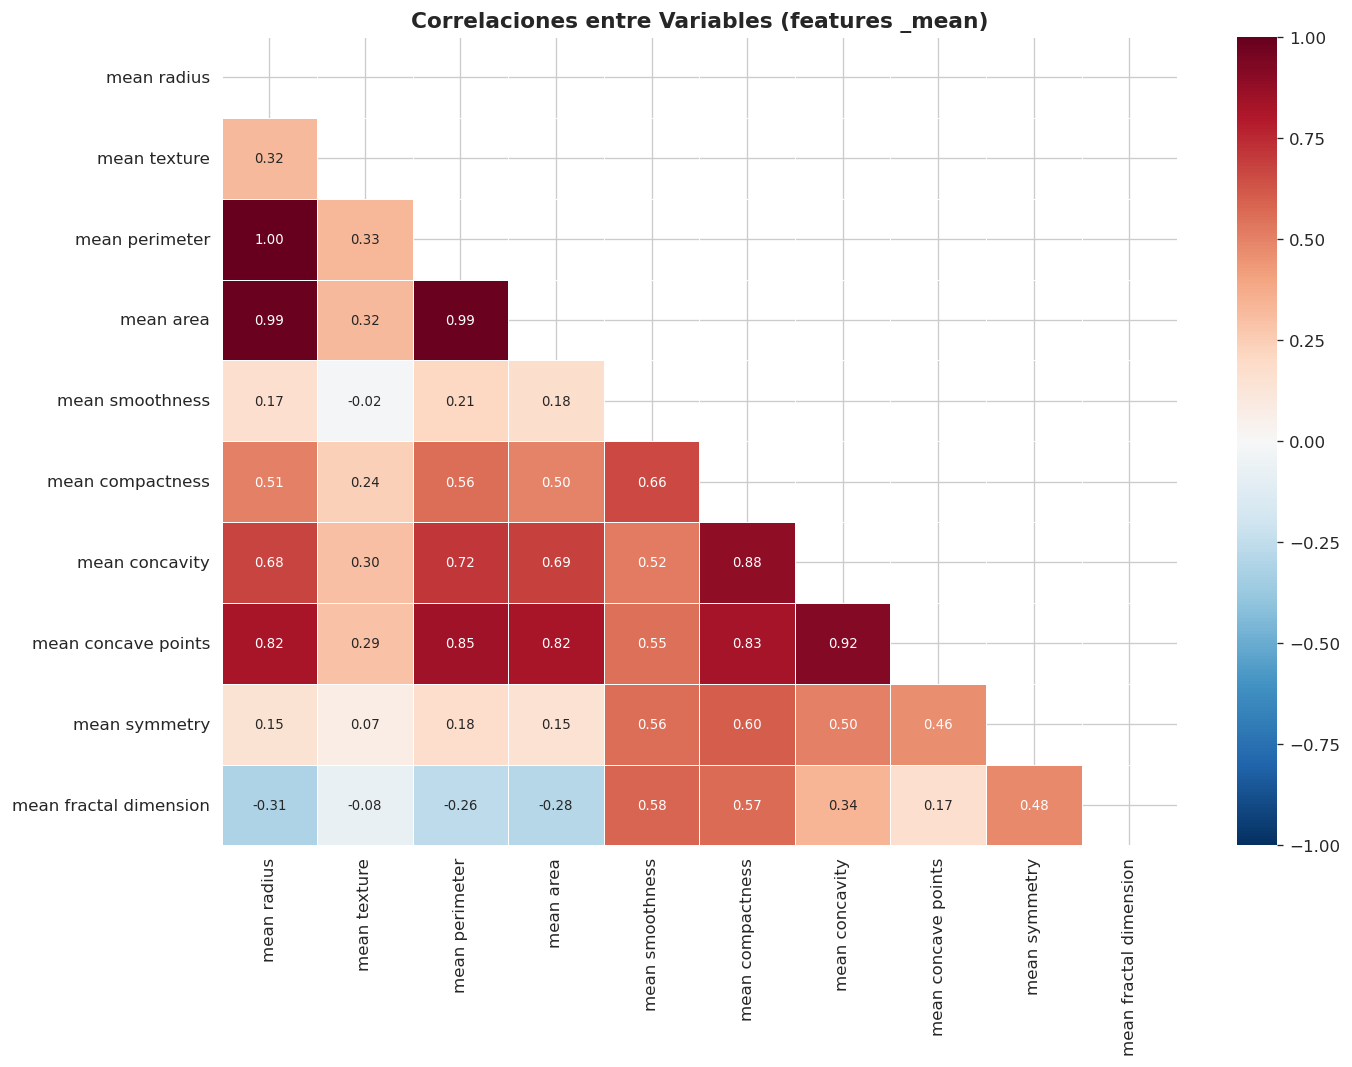

In [11]:
# Visualización 3: Mapa de correlaciones (heatmap)
# Solo variables _mean para no saturar
mean_cols = [c for c in bc.feature_names if 'mean' in c]
fig, ax = plt.subplots(figsize=(12, 9))

corr = df[mean_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # solo triángulo inferior

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={'size': 8})

ax.set_title('Correlaciones entre Variables (features _mean)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 💬 Tras el EDA:

1. ¿Qué variables les parecen más prometedoras para separar los grupos? ¿Por qué?
2. Las altas correlaciones entre variables, ¿son un problema o una oportunidad?
3. El dataset tiene 63% benigno / 37% maligno. ¿Afecta eso al clustering?

---

**✏️ Ejercicio 1:**
Elegí dos variables del heatmap con baja correlación entre sí (r < 0.3).
Graficá un scatterplot coloreando los puntos por diagnóstico. ¿Se pueden separar los grupos visualmente?
¿Qué pasa si elegís dos variables con alta correlación (r > 0.9)?

1. Las variables mas prometedoras son concavity, concave points, area and compactness. Ya que presentan distribucion bimodal y una separacion en la nube de puntos
   
2. Las altas correlaciones de las variables son una oprtunidad, ya que esta diciendo que hay covarianza entre las mismas y pueden usarse para comprimirlas en unas pocas variables. Es decir: Cuando tienes 30 variables en medicina, muchas de ellas suelen medir variaciones de lo mismo (por ejemplo: radio promedio, perímetro promedio y área promedio del tumor). Si están altamente correlacionadas, significa que tu dataset sufre de mucha redundancia.PCA tomará esas 30 variables correlacionadas y las comprimirá en 2 o 3 "Super-variables" (Componentes Principales) que capturan casi toda la información (varianza) original, eliminando la redundancia.
   
3. Los datos desparejos si afectan el clustering, por ende, hay que estandarizar los datos y usar una busqueda de parametros que pondere ese desbalance. En algoritmos supervisados, un desbalance extremo hace que el modelo ignore a la clase minoritaria. En clustering, los algoritmos no saben qué es "benigno" o "maligno", ellos solo buscan densidad y cercanía geométrica. Una proporción de 63/37 es, en realidad, un desbalance bastante moderado y muy saludable para el clustering.

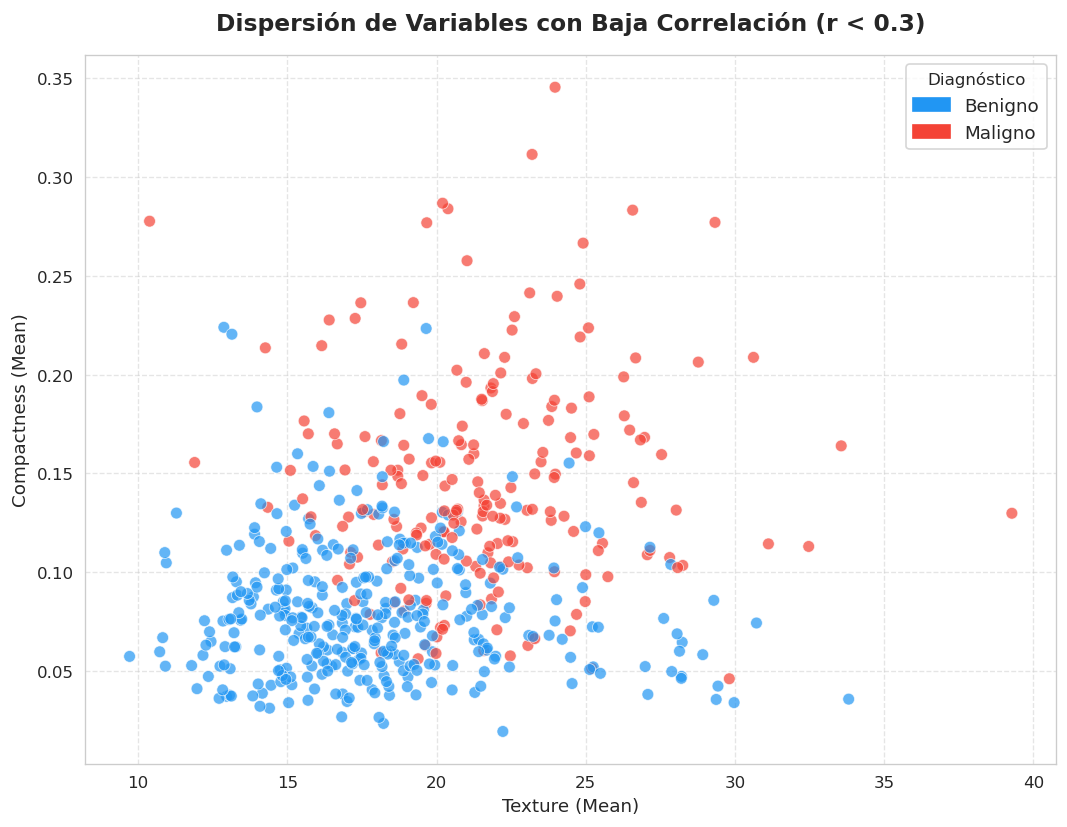

In [6]:
# Scatter plot de 2 variables con baja correlacion entre si y coloreada por diagnostico
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# 1. Seleccionamos dos variables con muy baja correlación (r < 0.3)
# Textura y Suavidad tienen una relación prácticamente nula.
vars_scatter = [
    'mean texture',
    'mean compactness'
]

# 2. Creamos el sub-dataframe y limpiamos los nombres para las etiquetas de los ejes
df_scatter = df[vars_scatter + ['diagnosis_label']].copy()
x_name = vars_scatter[0].replace('mean ', '').capitalize()
y_name = vars_scatter[1].replace('mean ', '').capitalize()

# 3. Configuramos el lienzo del gráfico
plt.figure(figsize=(9, 7))

# 4. Dibujamos el scatterplot usando Seaborn para mapear tus colores exactos
sns.scatterplot(
    data=df_scatter,
    x=vars_scatter[0],
    y=vars_scatter[1],
    hue='diagnosis_label',
    palette={'Benigno': '#2196F3', 'Maligno': '#F44336'},
    alpha=0.7,
    s=50,
    edgecolor='w',
    linewidth=0.5
)

# 5. Personalización de etiquetas y títulos basada en tu estilo
plt.title('Dispersión de Variables con Baja Correlación (r < 0.3)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel(f"{x_name} (Mean)", fontsize=11)
plt.ylabel(f"{y_name} (Mean)", fontsize=11)

# Creamos la leyenda usando tus parches manuales de matplotlib
leyenda = [
    mpatches.Patch(color='#2196F3', label='Benigno'),
    mpatches.Patch(color='#F44336', label='Maligno')
]
plt.legend(handles=leyenda, loc='upper right', fontsize=11, title='Diagnóstico')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

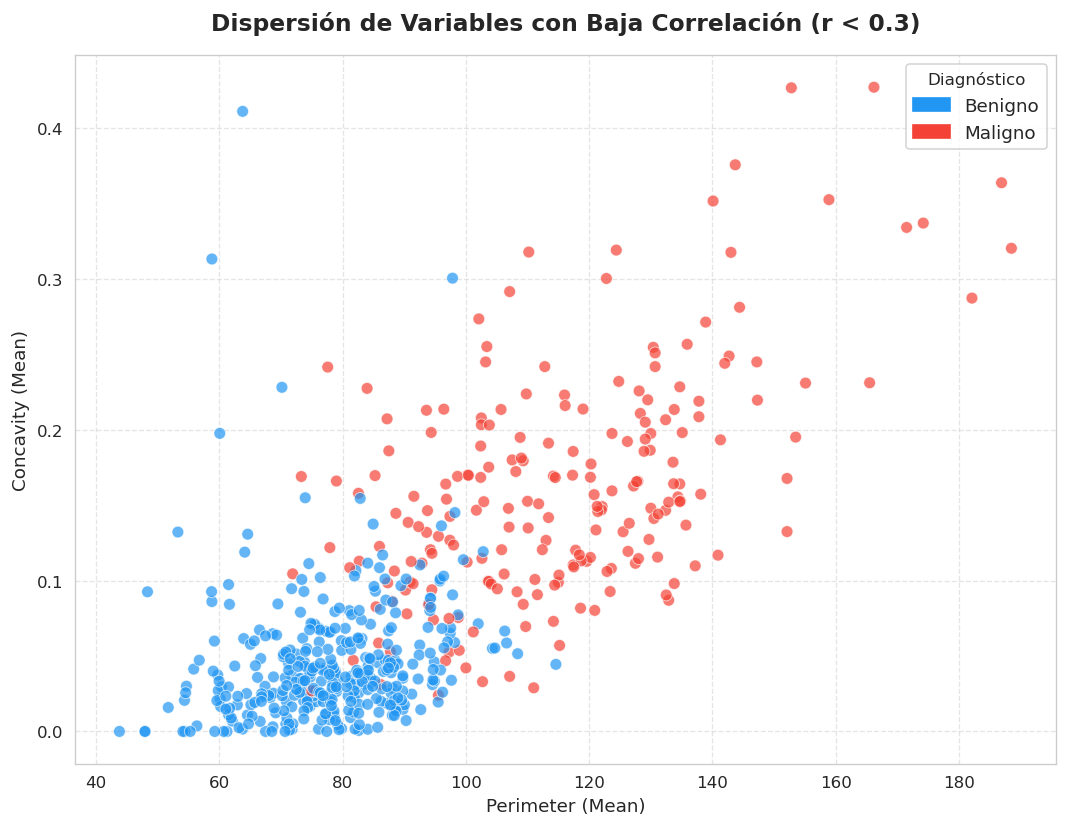

In [8]:
#Scatter plot de 2 variables altamente correlacionadas entre si coloreadas por diagnostico.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# 1. Seleccionamos dos variables con muy baja correlación (r < 0.3)
# Textura y Suavidad tienen una relación prácticamente nula.
vars_scatter = [
    'mean perimeter',
    'mean concavity'
]

# 2. Creamos el sub-dataframe y limpiamos los nombres para las etiquetas de los ejes
df_scatter = df[vars_scatter + ['diagnosis_label']].copy()
x_name = vars_scatter[0].replace('mean ', '').capitalize()
y_name = vars_scatter[1].replace('mean ', '').capitalize()

# 3. Configuramos el lienzo del gráfico
plt.figure(figsize=(9, 7))

# 4. Dibujamos el scatterplot usando Seaborn para mapear tus colores exactos
sns.scatterplot(
    data=df_scatter,
    x=vars_scatter[0],
    y=vars_scatter[1],
    hue='diagnosis_label',
    palette={'Benigno': '#2196F3', 'Maligno': '#F44336'},
    alpha=0.7,
    s=50,
    edgecolor='w',
    linewidth=0.5
)

# 5. Personalización de etiquetas y títulos basada en tu estilo
plt.title('Dispersión de Variables con Alta Correlación (r > 0.7)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel(f"{x_name} (Mean)", fontsize=11)
plt.ylabel(f"{y_name} (Mean)", fontsize=11)

# Creamos la leyenda usando tus parches manuales de matplotlib
leyenda = [
    mpatches.Patch(color='#2196F3', label='Benigno'),
    mpatches.Patch(color='#F44336', label='Maligno')
]
plt.legend(handles=leyenda, loc='upper right', fontsize=11, title='Diagnóstico')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

ANS: Aisladas de dos en dos, las variables con baja correlación parecen no servir para el clustering porque están mezcladas. Sin embargo, si combinas múltiples variables de baja correlación (es decir, agregas una 3ra dimensión, una 4ta, hasta llegar a las 30), esa mezcla bidimensional empieza a romperse.
Lo que en 2D parece un círculo mezclado, en un espacio de muchas dimensiones puede revelar que los puntos benignos están en el "centro" de una esfera hiperdimensional y los malignos forman una "coraza" externa, o que se separan usando un eje matemático oculto.

Justificando técnicamente por qué necesitas algoritmos multidimensionales o técnicas como PCA para encontrar la verdadera separación.

### 3. Reducción de dimensionalidad PCA

Con 30 variables en distintas escalas (área puede ser >1000, fractal dimension ≈ 0.05),
estandarizar es obligatorio antes de PCA.

FUNDAMENTO: El fundamento del PCA (Análisis de Componentes Principales) es simplificar un conjunto de datos complejo (con muchas variables) reduciendo su tamaño, pero perdiendo la menor cantidad de información posible. Para lograrlo, el PCA transforma las variables originales (que suelen estar correlacionadas) en un nuevo conjunto de variables llamadas Componentes Principales (CP). Para eso maximiza la varianza, la ortogonalidad y comprimir las dimensiones en 2 o 3. 

In [9]:
# Estandarizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA completo
pca_full = PCA()
scores_full = pca_full.fit_transform(X_scaled)    
var_exp  = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp) * 100   #Si me quedo con las primeras $K$ componentes, ¿qué porcentaje del dataset original estoy reteniendo
lambdas  = pca_full.explained_variance_      # esto es lo que agregás

#El algoritmo entrena (fit), calculando las nuevas direcciones o ejes del espacio, y luego proyecta o transforma (transform) tus datos escalados sobre esos nuevos ejes
#pca_full.explained_variance_ratio_:  lista donde cada elemento representa el porcentaje de información (varianza) que retiene cada componente de forma individual.
# lambdas  = pca_full.explained_variance: Da los Autovalores (o Lambdas $\lambda$) que son valores absolutos que resumen la varianza

print('Varianza explicada por las primeras 15 componentes:')
print(f'  {"CP":<6} {"Lambda":>10} {"Var (%)":>10} {"Acum (%)":>10}')
print('  ' + '-' * 42)
for i in range(10):
    print(f'  CP{i+1:<4} '
          f'{lambdas[i]:>10.4f} '
          f'{var_exp[i]*100:>9.1f}% '
          f'{var_acum[i]:>9.1f}%')

n80 = int(np.searchsorted(var_acum, 80)) + 1
n90 = int(np.searchsorted(var_acum, 90)) + 1
print(f'\nCPs para explicar 80% de la varianza: {n80}')
print(f'CPs para explicar 90% de la varianza: {n90}')
print(f'\nSuma de todos los lambdas: {lambdas.sum():.2f}  (= número de variables: {X.shape[1]})')

Varianza explicada por las primeras 10 componentes:
  CP         Lambda    Var (%)   Acum (%)
  ------------------------------------------
  CP1       13.3050      44.3%      44.3%
  CP2        5.7014      19.0%      63.2%
  CP3        2.8229       9.4%      72.6%
  CP4        1.9841       6.6%      79.2%
  CP5        1.6516       5.5%      84.7%
  CP6        1.2095       4.0%      88.8%
  CP7        0.6764       2.3%      91.0%
  CP8        0.4775       1.6%      92.6%
  CP9        0.4176       1.4%      94.0%
  CP10       0.3513       1.2%      95.2%

CPs para explicar 80% de la varianza: 5
CPs para explicar 90% de la varianza: 7

Suma de todos los lambdas: 30.05  (= número de variables: 30)


El criterio de Kaiser nos dice: Conserva solo las componentes con un autovalor (Lambda) mayor que 1.
En la práctica de Machine Learning y en la literatura médica, se considera excelente lograr retener entre el 75% y el 85% de la información original.

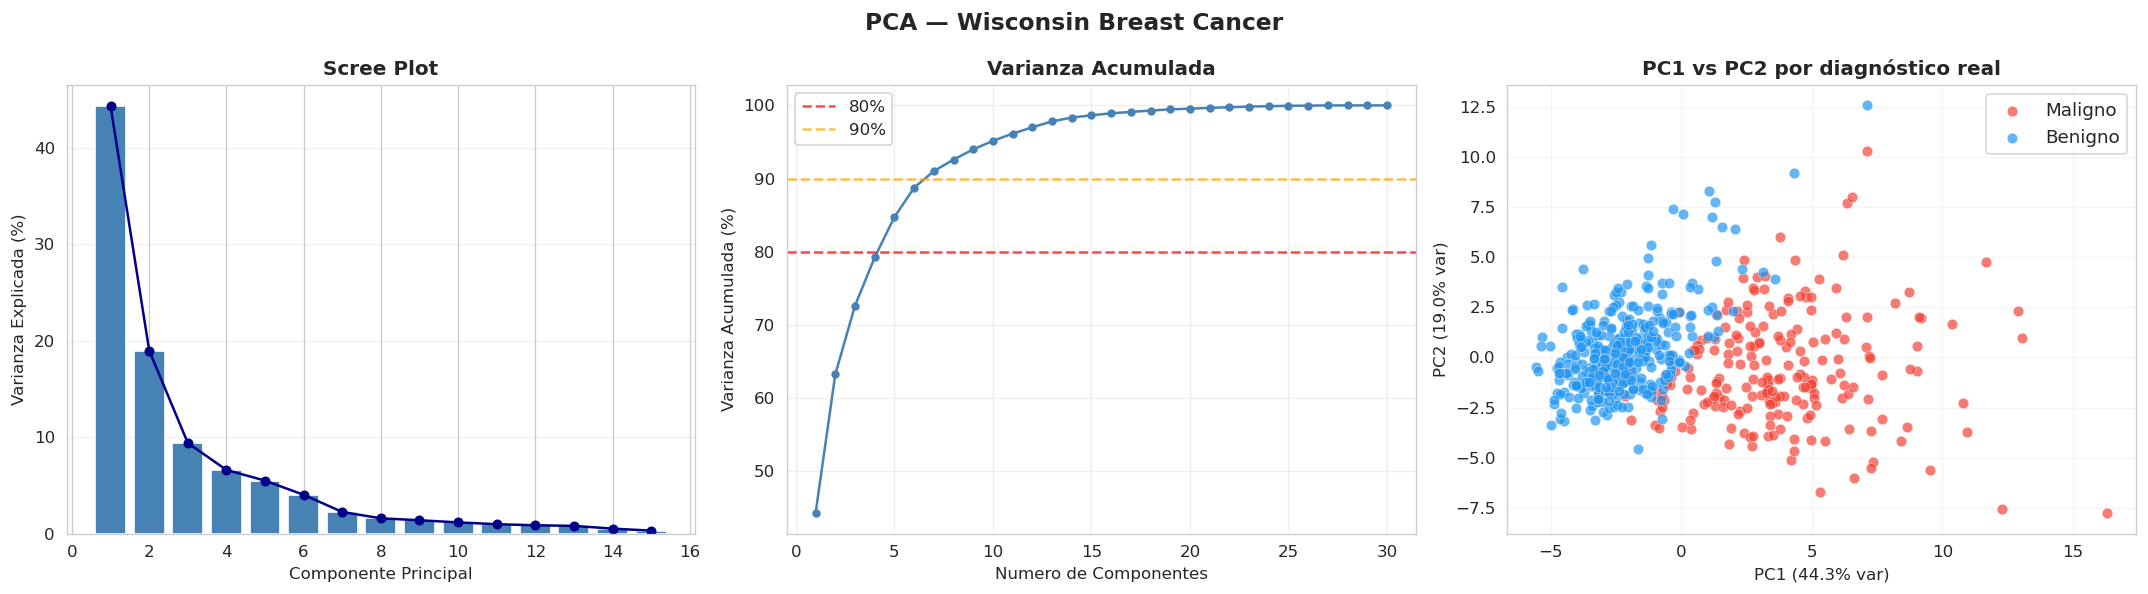

In [10]:
colores_diag = {0: '#F44336', 1: '#2196F3'}   # rojo=maligno, azul=benigno
nombres_diag = {0: 'Maligno', 1: 'Benigno'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('PCA — Wisconsin Breast Cancer', fontsize=14, fontweight='bold')

# Scree plot: este grafico es un histograma de la Var% que explica cada componente individual. 
ax = axes[0]
ax.bar(range(1, 16), var_exp[:15]*100, color='steelblue', edgecolor='white')
ax.plot(range(1, 16), var_exp[:15]*100, 'o-', color='darkblue', markersize=5)
ax.set_xlabel('Componente Principal')
ax.set_ylabel('Varianza Explicada (%)')
ax.set_title('Scree Plot', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Varianza acumulada: permite ver el corte del eje Y (var acumulada) que acumula 80% o mas de la variabilidad. 
ax = axes[1]
ax.plot(range(1, 31), var_acum, 'o-', color='steelblue', markersize=4)
ax.axhline(y=80, color='red', linestyle='--', alpha=0.7, label='80%')
ax.axhline(y=90, color='orange', linestyle='--', alpha=0.7, label='90%')
ax.set_xlabel('Numero de Componentes')
ax.set_ylabel('Varianza Acumulada (%)')
ax.set_title('Varianza Acumulada', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# PC1 vs PC2 coloreado por diagnóstico real
ax = axes[2]
for diag_val in [0, 1]:
    mask = y == diag_val
    ax.scatter(scores_full[mask, 0], scores_full[mask, 1],
               c=colores_diag[diag_val], label=nombres_diag[diag_val],
               s=40, alpha=0.7, edgecolors='white', linewidth=0.3)
ax.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}% var)')
ax.set_title('PC1 vs PC2 por diagnóstico real', fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

INTERPRETACION DEL GRAFICO PCA:
- El algoritmo, al combinar las 30 dimensiones, logró alinear la frontera de salud/enfermedad casi a la perfección a lo largo del eje horizontal (Componente 1). Esto demuestra que un algoritmo de aprendizaje no supervisado como K-Means va a tener una tasa de éxito altísima separando estos grupos, porque las nubes son geométricamente disjuntas.
- Notas un grupo masivo de flechas apuntando fuertemente hacia la derecha (como mean perimeter, mean area, mean radius, worst area, etc.). Esto significa que a mayor tamaño del tumor, más a la derecha se ubica el paciente en el gráfico. Está diciendo visualmente que los tumores malignos se caracterizan por valores extremadamente altos en perímetros, radios y áreas.
- El Solapamiento: En el centro del gráfico (cerca del valor 0 de la Componente 1) hay una pequeña franja donde se cruzan puntos azules y rojos. Esos son los "tumores de frontera"; casos malignos inusualmente pequeños o benignos con texturas sospechosas.
  
- Aplicación clínica: En lugar de analizar el radio, el perímetro, el área y la concavidad por separado, el PCA te permite crear una única métrica score (el valor en el eje X). Un paciente con un score de Componente 1 mayor a 4, por ejemplo, puede ser catalogado de forma automática como "Caso de Alta Sospecha Maligna". Esto simplifica la creación de sistemas de alerta temprana en hospitales.
- Aplicación clínica: El PCA aísla visualmente a los pacientes atípicos. Si un paciente aparece flotando completamente solo en una esquina del gráfico, el sistema le advierte al patólogo

In [11]:
# Crear DataFrame con los vectores de las componentes
# Filas = componentes, Columnas = variables originales
df_componentes = pd.DataFrame(
    pca_full.components_,
    columns=bc.feature_names,
    index=[f'CP{i+1}' for i in range(len(pca_full.components_))]
)

# Ver las primeras 10 componentes (son 30 en total)
print('Vectores de las primeras 10 componentes principales:')
print(df_componentes.iloc[:10].round(3).to_string())

Vectores de las primeras 10 componentes principales:
      mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension
CP1         0.219         0.104           0.228      0.221            0.143             0.239           0.258                0.261          0.138                   0.064         0.206          0.017            0.211       0.203             0.015              0.170            0.154                 0.183           0.042                    0.103         0.228          0.104            0.237       0.225             0.128       

El siguiente codigo es la continuación analítica del gráfico (Biplot) que acabamos de interpretar. Su propósito es ponerle números exactos a las flechas rojas de tu gráfico: calcula y ordena los Loadings (o cargas), que son los coeficientes numéricos que indican cuánta influencia tiene cada una de las 30 variables originales en la construcción de los nuevos componentes CP1 y CP2.

In [12]:
pca2 = PCA(n_components=2)
scores2 = pca2.fit_transform(X_scaled)

loadings = pca2.components_.T    # shape: (30, 2)

# Crear DataFrame con los loadings
df_loadings = pd.DataFrame(
    loadings,
    index=bc.feature_names,
    columns=['PC1', 'PC2']
)

# Agregar la magnitud (influencia total en ambas componentes)
df_loadings['magnitud'] = np.sqrt(df_loadings['PC1']**2 + df_loadings['PC2']**2)

# Tabla ordenada por PC1 (de mayor a menor valor absoluto)
print("=== Variables ordenadas por contribución a PC1 ===")
print(df_loadings[['PC1']].reindex(
    df_loadings['PC1'].abs().sort_values(ascending=False).index
).round(3).to_string())

print()

# Tabla ordenada por PC2
print("=== Variables ordenadas por contribución a PC2 ===")
print(df_loadings[['PC2']].reindex(
    df_loadings['PC2'].abs().sort_values(ascending=False).index
).round(3).to_string())

print()

# Tabla completa ordenada por magnitud total
print("=== Variables ordenadas por influencia total (PC1 + PC2) ===")
print(df_loadings.sort_values('magnitud', ascending=False).round(3).to_string())

=== Variables ordenadas por contribución a PC1 ===
                           PC1
mean concave points      0.261
mean concavity           0.258
worst concave points     0.251
mean compactness         0.239
worst perimeter          0.237
worst concavity          0.229
worst radius             0.228
mean perimeter           0.228
worst area               0.225
mean area                0.221
mean radius              0.219
perimeter error          0.211
worst compactness        0.210
radius error             0.206
area error               0.203
concave points error     0.183
compactness error        0.170
concavity error          0.154
mean smoothness          0.143
mean symmetry            0.138
worst fractal dimension  0.132
worst smoothness         0.128
worst symmetry           0.123
worst texture            0.104
mean texture             0.104
fractal dimension error  0.103
mean fractal dimension   0.064
symmetry error           0.042
texture error            0.017
smoothness error   

De la tabla anterior podemos concluir que: 
- Al mirar los números del PC1, todas las variables importantes tienen signos positivos. Esto significa que todas empujan en la misma dirección. Si el valor de estas variables sube, el paciente se mueve hacia la derecha del gráfico (zona maligna).Las variables reinas del PC1 son:mean concave points y mean concavity, mean compactness, worst perimeter y worst radius. El PC1 no mide solo el tamaño, mide la agresividad morfológica.
  
- El PC2 es el eje más interesante porque presenta un juego de signos positivos y negativos. Esto actúa matemáticamente como una balanza o un contraste. PC2 es un refinador médico: ayuda al algoritmo a distinguir entre un tumor que es peligroso porque es muy complejo (arriba) de uno que es peligroso porque es muy grande (abajo).

La tercer tabla PC1+PC2, al combinar el poder de ambos componentes mediante Pitágoras, elimina los signos y te dice cuáles son las variables que realmente contienen la información más valiosa de todo el estudio.El podio de variables más influyentes es:mean fractal dimension, mean radius y mean area. Si mañana tuvieras que diseñar un algoritmo de clustering ultra-eficiente, o si un hospital te pidiera reducir costes quitando variables para diagnosticar más rápido a los pacientes, esta última tabla te da la respuesta exacta. Podrías quedarte únicamente con las 5 o 6 variables que tienen una magnitud mayor a $0.30$


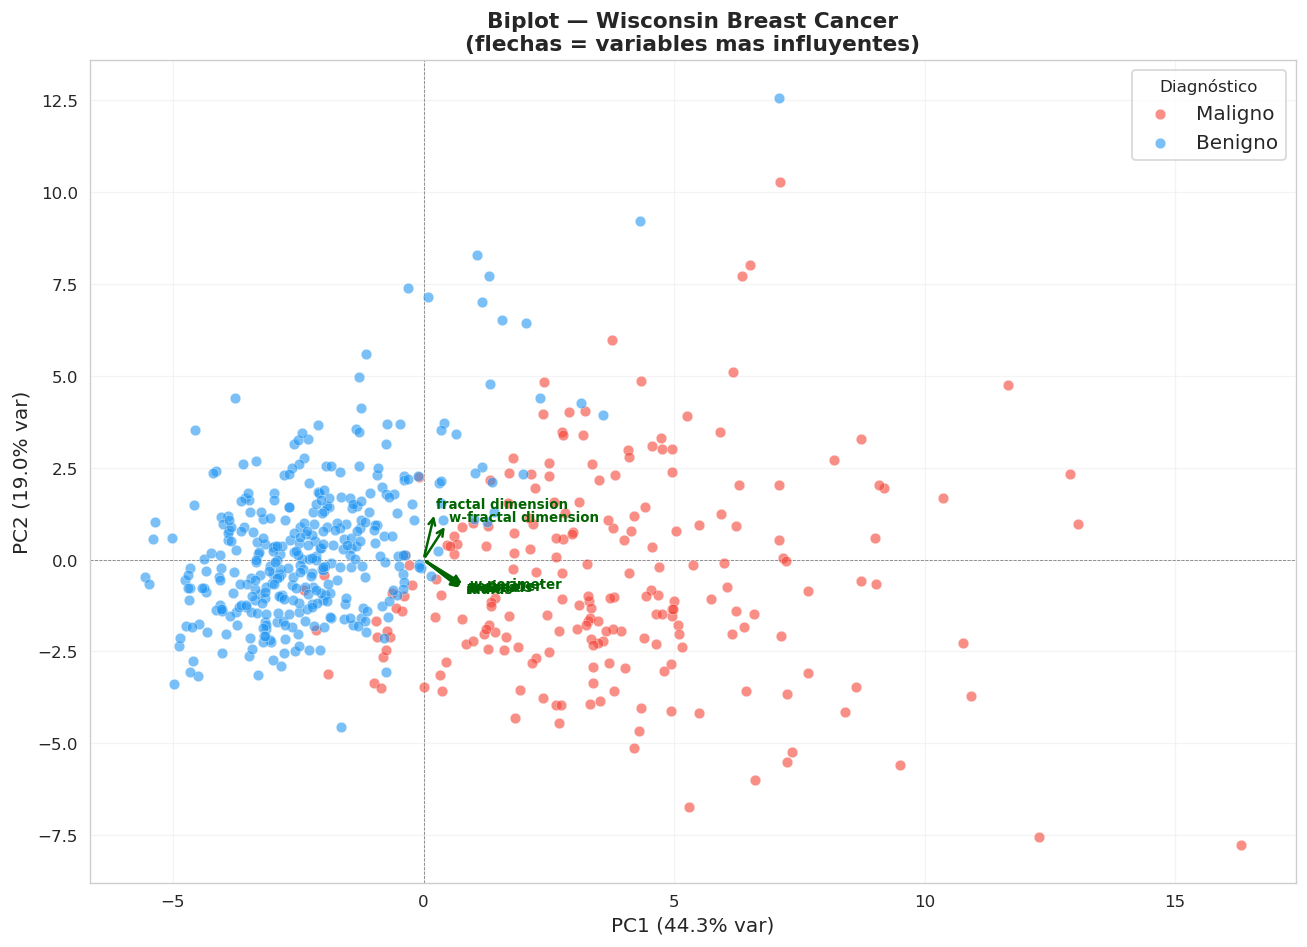

In [13]:
# Biplot: PC1 vs PC2 + loadings de las variables más influyentes
pca2 = PCA(n_components=2)
scores2 = pca2.fit_transform(X_scaled)

loadings = pca2.components_.T    # shape: (30, 2)
magnitudes = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
top_idx = np.argsort(magnitudes)[-8:]
feature_names = bc.feature_names
scale = 3.5

fig, ax = plt.subplots(figsize=(11, 8))

for diag_val in [0, 1]:
    mask = y == diag_val
    ax.scatter(scores2[mask, 0], scores2[mask, 1],
               c=colores_diag[diag_val], label=nombres_diag[diag_val],
               s=40, alpha=0.6, edgecolors='white', linewidth=0.3, zorder=3)

for idx in top_idx:
    ax.annotate('', xy=(loadings[idx, 0]*scale, loadings[idx, 1]*scale),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='darkgreen', lw=1.5))
    # Nombre más legible: quitar prefijo redundante
    nombre = feature_names[idx].replace('mean ', '').replace('worst ', 'w-')
    ax.text(loadings[idx, 0]*scale*1.1, loadings[idx, 1]*scale*1.1,
            nombre, fontsize=8, color='darkgreen', fontweight='bold')

ax.axhline(0, color='gray', lw=0.5, linestyle='--')
ax.axvline(0, color='gray', lw=0.5, linestyle='--')
ax.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% var)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% var)', fontsize=12)
ax.set_title('Biplot — Wisconsin Breast Cancer\n(flechas = variables mas influyentes)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=12, title='Diagnóstico')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [11]:
feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

### 💬 Preguntas disparadoras - PCA

1. ¿Por qué en Wisconsin PC1 explica mucho más varianza que en NCI60?

2. Mirando el biplot: ¿qué variables empujan hacia los malignos? ¿Tiene sentido clínico?

3. ¿Cuántas componentes usarían para el clustering? ¿Por qué no las 30?

---

**✏️ Ejercicio 2:**
Modificá el biplot para mostrar **todas** las flechas de las 30 variables en lugar de las 8 principales.
¿Qué observás? ¿Hay variables que apuntan en dirección opuesta? ¿Qué significa eso clínicamente?

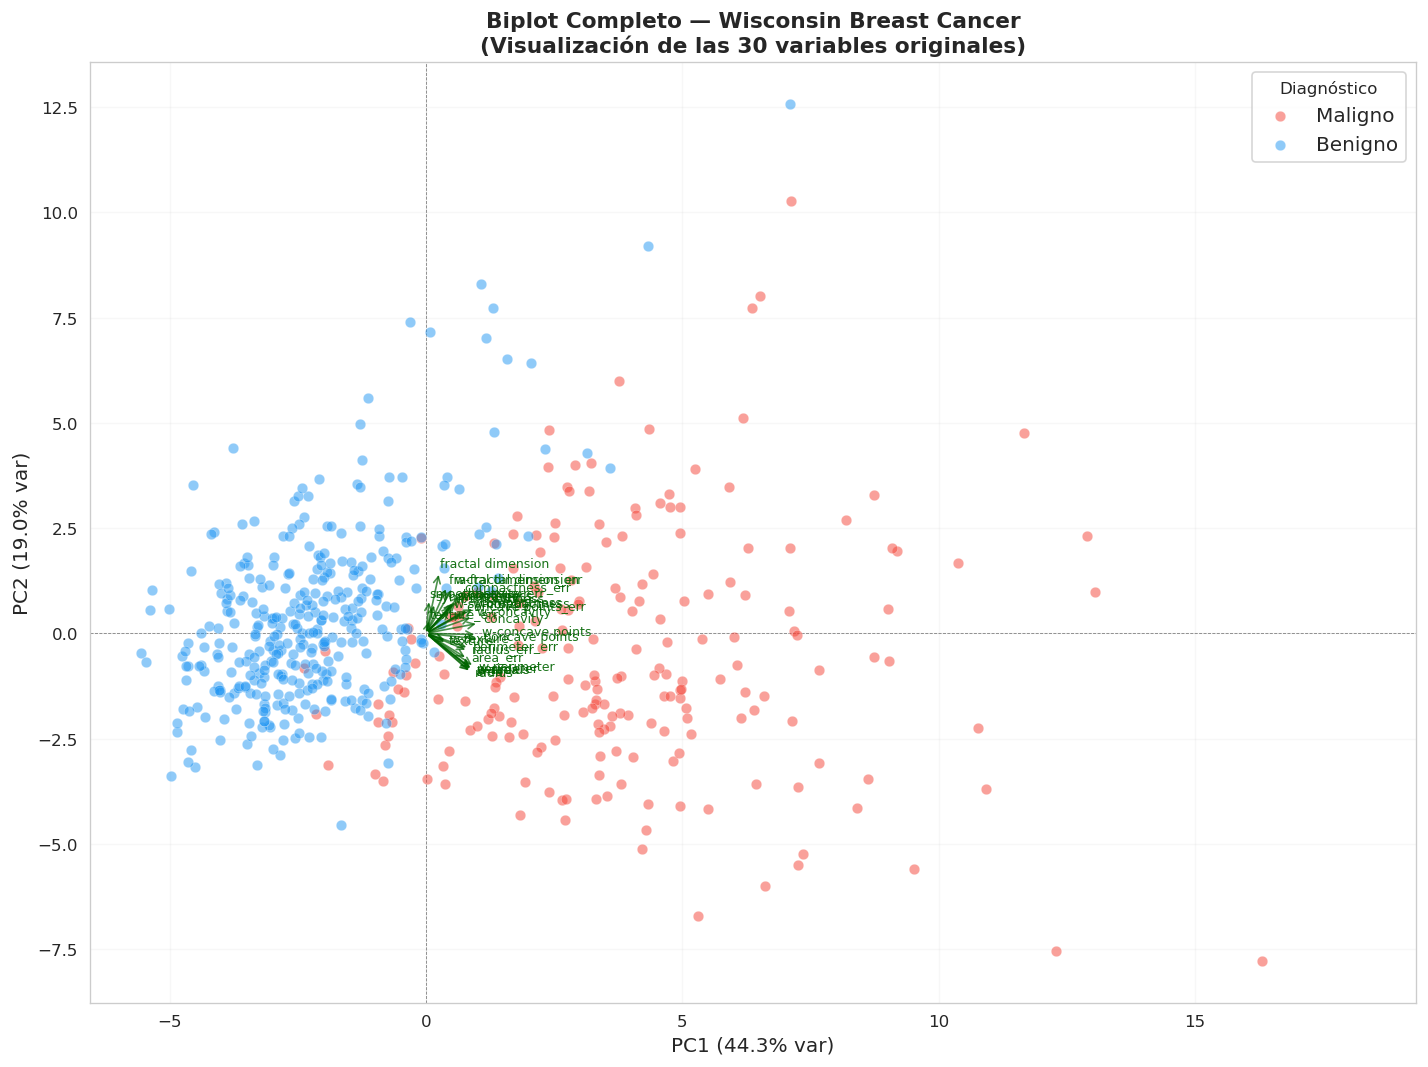

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Calculamos el PCA con TODAS las componentes posibles (30 en este caso)
pca_full = PCA()  # Al no poner número, calcula las 30 componentes
scores_full = pca_full.fit_transform(X_scaled)

# 2. Extraemos los loadings para todas las variables
# Aunque calculamos 30 componentes, para los ejes del gráfico usaremos los pesos en PC1 y PC2
loadings = pca_full.components_.T    # shape: (30, 30)

feature_names = bc.feature_names
scale = 4.0  # Incrementé un poco la escala para dar espacio a las 30 flechas

fig, ax = plt.subplots(figsize=(12, 9))

# 3. Graficar los puntos usando las coordenadas de PC1 (columna 0) y PC2 (columna 1)
for diag_val in [0, 1]:
    mask = y == diag_val
    ax.scatter(scores_full[mask, 0], scores_full[mask, 1],
               c=colores_diag[diag_val], label=nombres_diag[diag_val],
               s=40, alpha=0.5, edgecolors='white', linewidth=0.3, zorder=3)

# 4. Graficar las flechas de las 30 variables (recorremos todos los índices del 0 al 29)
for idx in range(len(feature_names)):
    # Usamos loadings[idx, 0] para el eje X (PC1) y loadings[idx, 1] para el eje Y (PC2)
    ax.annotate('', xy=(loadings[idx, 0]*scale, loadings[idx, 1]*scale),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='darkgreen', lw=1.0, alpha=0.7))
    
    # Formateo de nombre para que no se sature tanto el gráfico
    nombre = feature_names[idx].replace('mean ', '').replace('worst ', 'w-').replace(' error', '_err')
    
    # Desplazamiento del texto para las etiquetas
    ax.text(loadings[idx, 0]*scale*1.08, loadings[idx, 1]*scale*1.08,
            nombre, fontsize=7.5, color='darkgreen', alpha=0.9, zorder=5)

# 5. Configuración de líneas guía y etiquetas dinámicas
ax.axhline(0, color='gray', lw=0.5, linestyle='--')
ax.axvline(0, color='gray', lw=0.5, linestyle='--')

# Mostramos el porcentaje real de varianza de las dos primeras componentes del PCA completo
ax.set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% var)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% var)', fontsize=12)

ax.set_title('Biplot Completo — Wisconsin Breast Cancer\n(Visualización de las 30 variables originales)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=12, title='Diagnóstico')
ax.grid(alpha=0.15)

# Ajustamos los límites para asegurarnos de que todas las flechas y textos sean visibles
ax.set_xlim(scores_full[:, 0].min() - 1, scores_full[:, 0].max() + 3)
ax.set_ylim(scores_full[:, 1].min() - 1, scores_full[:, 1].max() + 1)

plt.tight_layout()
plt.show()

2. Las variables que mas empujan hacia los malignos son mean fractal dimension, fractal dimension error, worst fractal dimension y worst perimeter. Estas variables indican que  los pacientes con tumores de gran tamaño y forma irregular tendran probablemente tumores malignos. Cuanto mas positivas estas variables mas chances que sea maligno.

3. USaria 5-6 componentes que expliquen el 90% de la varianza y que tengan un loading superior a 0.3 en los PCAs.

4. La fractal dimension apunta arriba y a la izquierda, porque tiene correlacion inversa. Eso quiere decir que un tumor con alta irregularidad probable sea benigno siempre cuando sea pequeño. 

## 4. K-Means Clustering

Aplicamos K-Means sobre las **primeras 5 componentes principales**, que explican ~80% de la varianza.
Buscamos K=2 porque sabemos que hay dos grupos clínicos (pero también exploraremos otros valores).

¿Cuál es el número óptimo de grupos ($K$) en los que se deben dividir mis pacientes? Aunque tú sabes en secreto que hay 2 diagnósticos (benigno y maligno), el algoritmo no lo sabe, y este código sirve para justificar estadísticamente por qué $K=2$ es la mejor elección.

Para saber qué $K$ es el mejor, el código pone a competir diferentes escenarios haciendo un experimento: ejecuta el algoritmo K-Means variando el número de grupos desde $K=2$ hasta $K=10$ (K_range). En cada iteración, entrena el modelo y calcula dos métricas de rendimiento indispensables:
- La Inercia (o WCSS - Within-Cluster Sum of Squares): Mide qué tan compactos están los puntos dentro de su propio grupo calculando la distancia de cada paciente al centro de su cluster.
- El Silhouette Score (Coeficiente de Silueta): Mide la calidad global del clustering evaluando dos cosas a la vez: qué tan cerca está un paciente de su propio grupo (cohesión) y qué tan lejos está del grupo vecino (separación). Va de -1 a 1


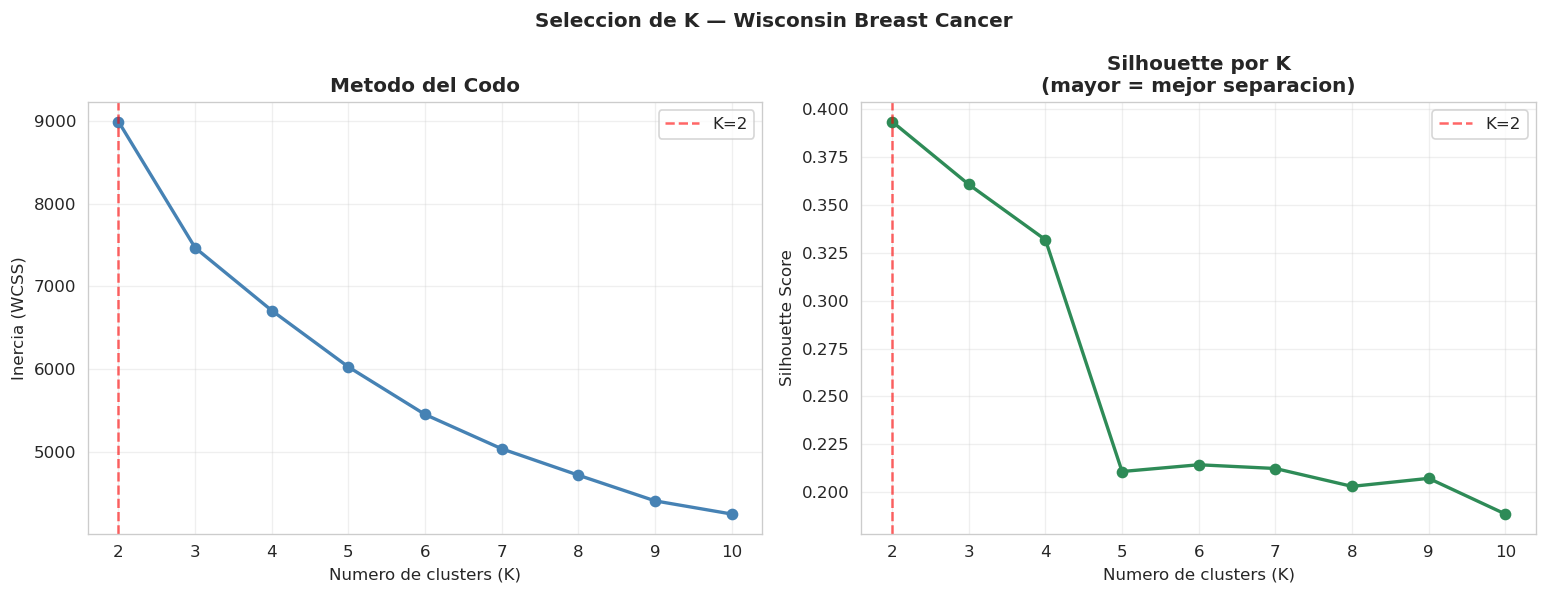

In [16]:
# Reducir a 5 CPs para clustering (~80% varianza)
pca5 = PCA(n_components=5)
scores5 = pca5.fit_transform(X_scaled)

# Método del codo
inercias = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = km.fit_predict(scores5)
    inercias.append(km.inertia_)
    sil_scores.append(silhouette_score(scores5, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Seleccion de K — Wisconsin Breast Cancer', fontweight='bold')

ax = axes[0]
ax.plot(list(K_range), inercias, 'o-', color='steelblue', linewidth=2)
ax.axvline(x=2, color='red', linestyle='--', alpha=0.6, label='K=2')
ax.set_xlabel('Numero de clusters (K)')
ax.set_ylabel('Inercia (WCSS)')
ax.set_title('Metodo del Codo', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(list(K_range), sil_scores, 'o-', color='seagreen', linewidth=2)
ax.axvline(x=2, color='red', linestyle='--', alpha=0.6, label='K=2')
ax.set_xlabel('Numero de clusters (K)')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette por K\n(mayor = mejor separacion)', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

El codo esta alrededor de 2-3 clusters, que es donde empieza a caer la inercia. Si vemos el silohuete, el punto más alto de la gráfica es el ganador. 

In [17]:
# K-Means con K=2
km2 = KMeans(n_clusters=2, random_state=42, n_init=50)
labels_km = km2.fit_predict(scores5)

ari_km = adjusted_rand_score(y, labels_km)
sil_km = silhouette_score(scores5, labels_km)

print(f'ARI  = {ari_km:.3f}  (0=aleatorio, 1=perfecto)')
print(f'Silhouette = {sil_km:.3f}')
print()

# Matriz de confusión
# Alinear etiquetas: K-Means puede asignar 0 al benigno o al maligno
# Probamos las dos orientaciones y nos quedamos con la mejor
cm1 = confusion_matrix(y, labels_km)
cm2 = confusion_matrix(y, 1 - labels_km)
cm = cm1 if cm1.diagonal().sum() >= cm2.diagonal().sum() else cm2

print('Matriz de confusion (diagnóstico real vs cluster asignado):')
print(f'             Cluster 0   Cluster 1')
print(f'  Maligno    {cm[0,0]:6d}      {cm[0,1]:6d}')
print(f'  Benigno    {cm[1,0]:6d}      {cm[1,1]:6d}')
print()
correctos = cm.diagonal().sum()
print(f'Casos correctamente agrupados: {correctos}/569 ({correctos/569*100:.1f}%)')

ARI  = 0.671  (0=aleatorio, 1=perfecto)
Silhouette = 0.393

Matriz de confusion (diagnóstico real vs cluster asignado):
             Cluster 0   Cluster 1
  Maligno       175          37
  Benigno        14         343

Casos correctamente agrupados: 518/569 (91.0%)


ARI = 0.671 (Adjusted Rand Index): El ARI mide la concordancia entre los clusters encontrados y las etiquetas reales, corregido por el azar. Un valor de 0.671 se considera muy alto en la literatura científica de clustering. 

El algoritmo metió en el Cluster 0 a 175 tumores Malignos y solo a 14 Benignos. Lectura médica: El Cluster 0 es, con un alto grado de certeza, la población enferma.
El algoritmo asignó aquí a 343 tumores Benignos y a 37 Malignos. Lectura médica: El Cluster 1 representa la población sana. Sin embargo, clínicamente aquí es donde está el punto crítico: los 37 tumores malignos que el algoritmo clasificó como benignos.

¿Te acuerdas de tu segunda pregunta al principio de todo? Me preguntaste si el desbalance del dataset afectaría al clustering. Aquí tienes la respuesta empírica: Como el dataset tiene más casos benignos (63%) que malignos (37%), el centroide del Cluster 1 (Benigno) ejerció una "fuerza de atracción" matemática más grande debido a la densidad de puntos. Como consecuencia, el algoritmo estiró un poco la frontera hacia el lado benigno, provocando que 37 casos malignos de frontera cayeran del lado del Cluster 1.

Para corregir esos 37 casos malignos ocultos en el grupo sano (Cluster 1), el siguiente paso científico no sería usar distancias geométricas puras, sino probar con un modelo GMM (Modelos de Mezcla Gaussiana).

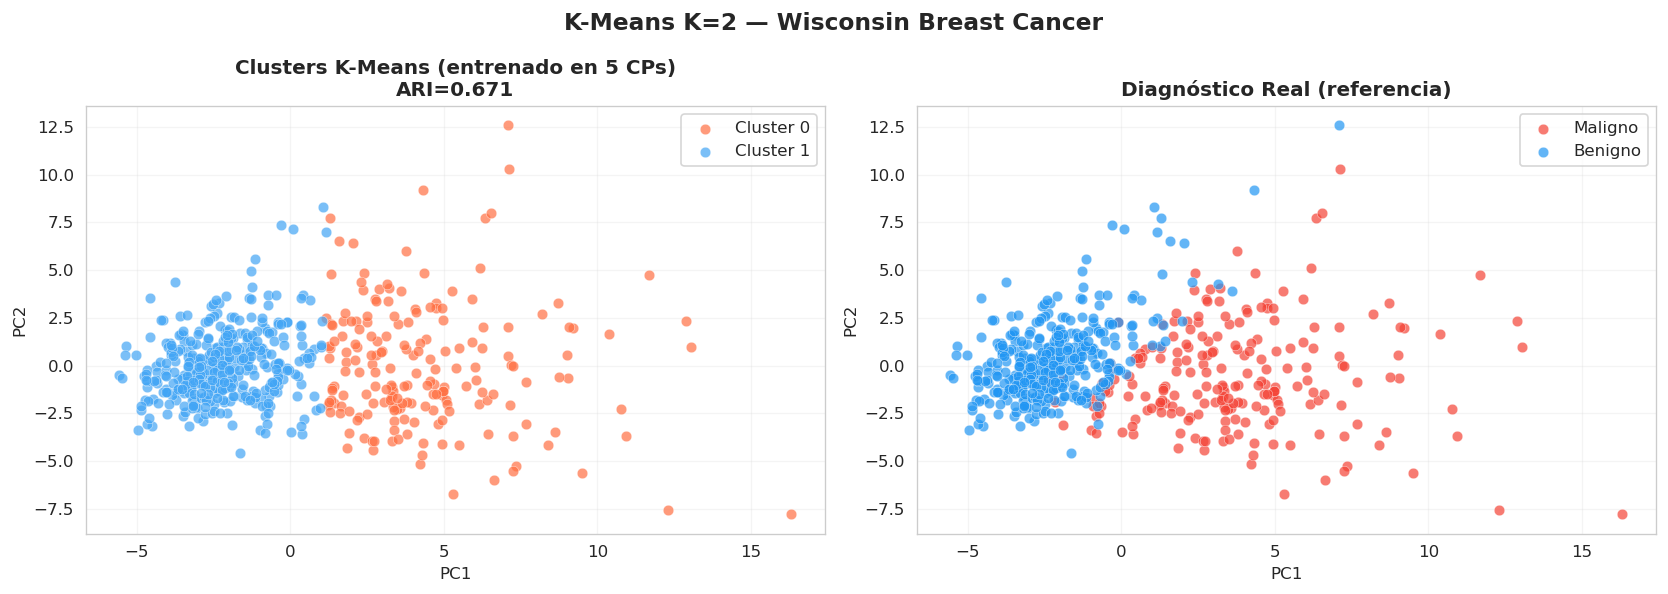

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('K-Means K=2 — Wisconsin Breast Cancer', fontsize=14, fontweight='bold')

colores_cluster = {0: '#FF7043', 1: '#42A5F5'}

# Clusters del algoritmo (coloreado por cluster asignado)
ax = axes[0]
for cl in [0, 1]:
    mask = labels_km == cl   # labels_km viene del K-Means en 5D
    ax.scatter(scores2[mask, 0], scores2[mask, 1],
               c=colores_cluster[cl], label=f'Cluster {cl}',
               s=40, alpha=0.7, edgecolors='white', linewidth=0.3)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title(f'Clusters K-Means (entrenado en 5 CPs)\nARI={ari_km:.3f}', fontweight='bold')
ax.legend()
ax.grid(alpha=0.2)

# Diagnóstico real
ax = axes[1]
for diag_val in [0, 1]:
    mask = y == diag_val
    ax.scatter(scores2[mask, 0], scores2[mask, 1],
               c=colores_diag[diag_val], label=nombres_diag[diag_val],
               s=40, alpha=0.7, edgecolors='white', linewidth=0.3)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('Diagnóstico Real (referencia)', fontweight='bold')
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 💬 Preguntas disparadoras — K-Means

1. El método del codo confirma K=2. ¿Qué pasaría si no supiéramos que hay 2 grupos?
2. ¿Cuántos malignos clasificó el algoritmo como benignos? ¿Qué implicancia clínica tiene eso?
3. Si tuviesen que elegir entre minimizar falsos negativos o falsos positivos, ¿qué elegirían? ¿Depende del contexto?

---

**✏️ Ejercicio 3:**
Corré K-Means directamente sobre los 30 features originales (sin PCA).
Comparás el ARI con el que obtuviste usando PCA. ¿Mejora o empeora?
¿A qué atribuís la diferencia?

1. Si estuviéramos ante una enfermedad completamente nueva y desconocida (donde no sabemos que hay 2 grupos), el método del codo y el Silhouette Score actuando en conjunto nos darían la máxima evidencia matemática de que la naturaleza de esta enfermedad se divide de forma óptima en dos variantes o estados biológicos bien diferenciados

2. CLasifico 37 tumores malignos como benignos, es decir, 37 falsos negativos. Por ende estas diagnoticando pacientes con tumores como sanos.

3. Para mi trataria minimizar falsos negativos, ya que en oncologia suelen ser letales. Obviamente depende de la gravedad de la enfermedad y el trabajo clinico (tratamiento, intervenciones,etc.). Preferimos mil veces un modelo paranoico que asuste a un paciente sano por error (Falso Positivo) y lo obligue a hacerse una segunda prueba de confirmación, a un modelo negligente que deje ir a un paciente enfermo a su casa a morir (Falso Negativo).

## 5. Clustering Jerárquico

El clustering jerárquico construye un árbol completo de fusiones.
En Wisconsin es especialmente interesante porque podemos ver si el árbol
se divide naturalmente en dos ramas (maligno/benigno).

Mientras que K-Means intenta dividir los datos de golpe en $K$ cajas rígidas obligando a los tumores a pertenecer a una o a otra, el Clustering Jerárquico construye una estructura de parentesco o árboles de decisión. 

El algoritmo calcula la distancia entre absolutamente todos los pacientes. Luego, busca a los dos pacientes que estén más cerca en el espacio matemático (los más "parecidos" clínicamente) y los fusiona en un nuevo cluster de 2 personas. El algoritmo repite este proceso de emparejamiento una y otra vez. En cada paso, los pacientes más similares se van uniendo a parejas existentes, o las parejas se unen entre sí para formar familias más grandes. El proceso no se detiene hasta que todos los pacientes de tu dataset quedan atrapados dentro de un único gran cluster gigante.

A diferencia de K-Means, el clustering jerárquico te da dos ventajas clínicas espectaculares:
- No tienes que predefinir $K$ antes de empezar: El algoritmo hace todo el árbol.
- Revela jerarquías reales: Te permite ver si un tumor maligno específico está más emparentado con la familia de tumores benignos que con la suya propia, ayudándote a rastrear de forma visual esos 37 casos complejos (falsos negativos) que confundieron al K-Means.

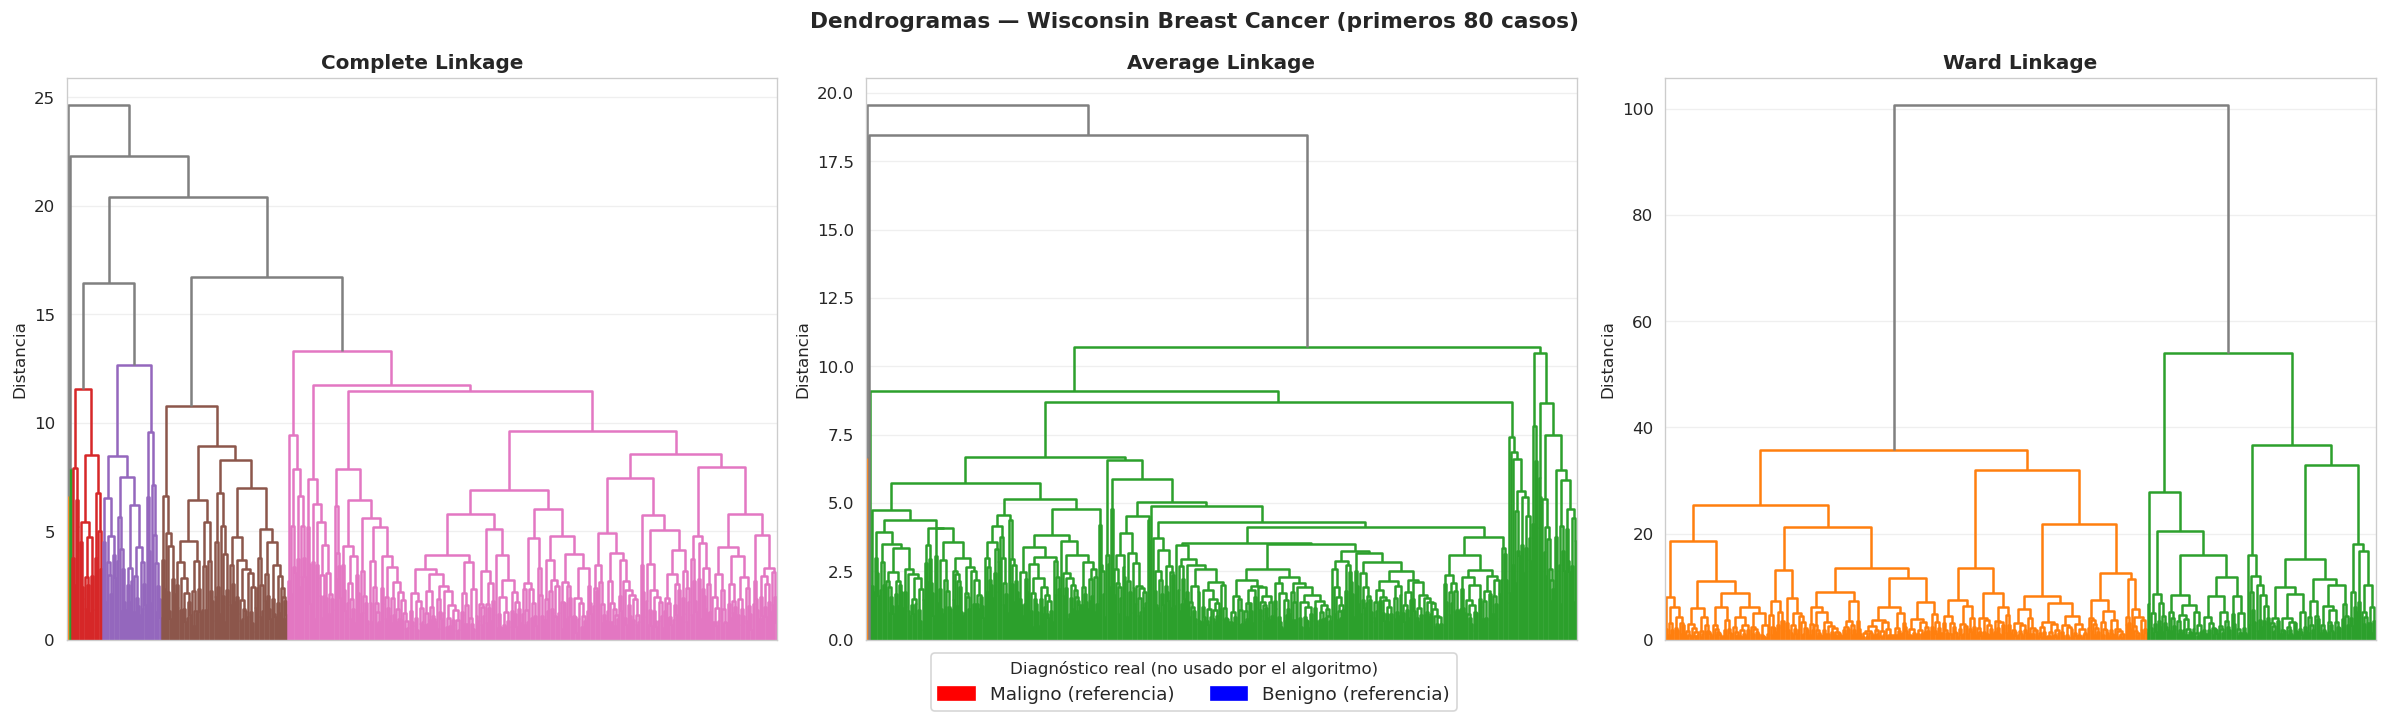

In [19]:
Z_complete = linkage(scores5, method='complete')
Z_average  = linkage(scores5, method='average')
Z_ward     = linkage(scores5, method='ward')    # Ward minimiza la varianza intra-cluster

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Dendrogramas — Wisconsin Breast Cancer (primeros 80 casos)',
             fontsize=13, fontweight='bold')

# Colores de hojas según diagnóstico real
diag_colors = np.where(y == 0, 'red', 'blue')

for ax, Z, title in zip(axes,
                          [Z_complete, Z_average, Z_ward],
                          ['Complete Linkage', 'Average Linkage', 'Ward Linkage']):
    dend = dendrogram(Z, ax=ax,
                      no_labels=True,
                      color_threshold=0.6*max(Z[:, 2]),
                      above_threshold_color='gray')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Distancia')
    ax.grid(axis='y', alpha=0.3)

# Leyenda manual
parches = [mpatches.Patch(color='red', label='Maligno (referencia)'),
           mpatches.Patch(color='blue', label='Benigno (referencia)')]
fig.legend(handles=parches, loc='lower center', ncol=2, fontsize=11,
           title='Diagnóstico real (no usado por el algoritmo)')

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

El script toma las 5 Componentes Principales que calculaste antes (scores5), construye los tres árboles genealógicos invertidos (dendrogramas) usando diferentes reglas de enlace, y los grafica lado a lado para que puedas comparar su estructura geométrica: 

Si miras el gráfico de la derecha, la estructura es hermosamente simétrica y balanceada. La Geometría: El árbol se divide en dos grandes ramas principales (una naranja a la izquierda y una verde a la derecha) que se unen a una distancia muy alta (cercana a 100). Las dos ramas tienen sub-árboles con alturas y densidades muy similares.

Interpretación Médica: Ward es el método que mejor entendió la naturaleza dual del dataset. Al minimizar la varianza interna, agrupó de forma muy compacta a los pacientes. Si pasas un corte horizontal por la línea gris superior, obtendrás exactamente 2 grupos masivos, limpios y equilibrados. Al comparar esto con tu scatter plot de PCA (donde viste dos nubes compactas), notas que Ward leyó a la perfección esa separación física entre benignos y malignos.

In [20]:
# Comparar linkages cortando en K=2
print(f'{'Linkage':<12} {'ARI':>8} {'Silhouette':>12} {'Davies-Bouldin':>16} {'% correcto':>12}')
print('-' * 65)

resultados_h = {}
for nombre, Z in [('Complete', Z_complete), ('Average', Z_average), ('Ward', Z_ward)]:
    lh = fcluster(Z, t=2, criterion='maxclust') - 1
    ari = adjusted_rand_score(y, lh)
    sil = silhouette_score(scores5, lh)
    db  = davies_bouldin_score(scores5, lh)
    cm1 = confusion_matrix(y, lh)
    cm2 = confusion_matrix(y, 1 - lh)
    cm  = cm1 if cm1.diagonal().sum() >= cm2.diagonal().sum() else cm2
    pct = cm.diagonal().sum() / len(y) * 100
    resultados_h[nombre] = (lh, ari, sil, db, pct)
    print(f'{nombre:<12} {ari:8.3f} {sil:12.3f} {db:16.3f} {pct:11.1f}%')

Linkage           ARI   Silhouette   Davies-Bouldin   % correcto
-----------------------------------------------------------------
Complete        0.005        0.666            0.412        63.1%
Average         0.005        0.666            0.412        63.1%
Ward            0.538        0.377            1.224        86.8%


EXPLICACION LINKAGES:
Enlace Completo (Complete Linkage): Mide la distancia entre los dos pacientes más lejanos de cada grupo. Tiende a buscar clusters muy compactos y esféricos.

Enlace Promedio (Average Linkage): Calcula la distancia promedio entre todos los pares de pacientes. Es muy estable frente al ruido.

Método de Ward (Ward's Linkage): En lugar de medir distancias directas, busca unir los grupos que minimicen el aumento de la varianza interna. El método de Ward intenta que los clusters resultantes sean lo más homogéneos y densos posible.

Viendo los valores de linkage, Ward            0.538        0.377            1.224        86.8%. 
ARI = 0.538 (que tan buena es la agrupacion con respecto a las etiquetas reales) y % correcto = 86.8%: Ward demuestra ser el único método jerárquico robusto para este problema. Logró identificar y separar de forma genuina a las dos poblaciones


### 💬 Preguntas disparadoras — Clustering Jerárquico

1. ¿En qué se parecen y en qué difieren los tres dendrogramas?
2. ¿A qué altura cortarían el árbol si no supieran que hay 2 grupos?
3. ¿Por qué Ward suele superar a complete y average en este tipo de datos?

---

**✏️ Ejercicio 4:**
Cortá el dendrograma de Ward en K=3 en lugar de K=2. ¿Qué nuevo grupo aparece?
¿Podrías interpretar clínicamente ese tercer cluster?
Pista: mirá qué diagnósticos reales caen en cada uno.

1. Se parecen en que comparten la base del arbol y las presencias de anomalias.Sin embargo, Ward se bifurca tempranamente en 2 ramas, en tanto que complete y average sufren estancamiento.

2. Si no supiera que k = 2, la regla de oro para cortar un dendrograma es buscar la línea horizontal imaginaria que cruce las líneas verticales más largas del gráfico (donde haya más espacio vacío vertical sin uniones).En Ward Linkage: El corte ideal se haría a una altura aproximada de 50 o 60. Si trazas una línea horizontal ahí, cortarás exactamente los dos grandes brazos grises que bajan desde la cima. Esto te daría de forma natural $K=2$ grupos.En Complete Linkage: El espacio vertical libre más largo está entre la distancia 6 y 8. Si cortas a la mitad (altura de 7), interceptas los 4 brazos principales, sugiriendo un $K=4$.

3. Tanto Complete (distancia máxima) como Average (distancia promedio) se dejan arrastrar fácilmente por los valores extremos. Ward funciona al revés: en cada paso, calcula el centro geométrico (centroide) de los grupos y evalúa cuánto aumentaría la dispersión total si los uniera.

In [21]:
#Genero linkage con K = 3
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score

# Comparar linkages cortando en K=3
print(f"{'Linkage':<12} {'ARI':>8} {'Silhouette':>12} {'Davies-Bouldin':>16}")
print('-' * 53)

resultados_h3 = {}

for nombre, Z in [('Complete', Z_complete), ('Average', Z_average), ('Ward', Z_ward)]:
    # CAMBIO PRINCIPAL: t=3 para forzar la creación de 3 clusters
    # Restamos 1 para que las etiquetas vayan de 0 a 2 (en lugar de 1 a 3)
    lh = fcluster(Z, t=3, criterion='maxclust') - 1
    
    # El ARI sigue funcionando perfecto porque mide consistencia de particiones externas
    ari = adjusted_rand_score(y, lh)
    
    # Métricas de evaluación interna (no necesitan 'y')
    sil = silhouette_score(scores5, lh)
    db  = davies_bouldin_score(scores5, lh)
    
    resultados_h3[nombre] = (lh, ari, sil, db)
    print(f"{nombre:<12} {ari:8.3f} {sil:12.3f} {db:16.3f}")

Linkage           ARI   Silhouette   Davies-Bouldin
-----------------------------------------------------
Complete        0.002        0.574            0.520
Average         0.003        0.631            0.356
Ward            0.484        0.368            1.330


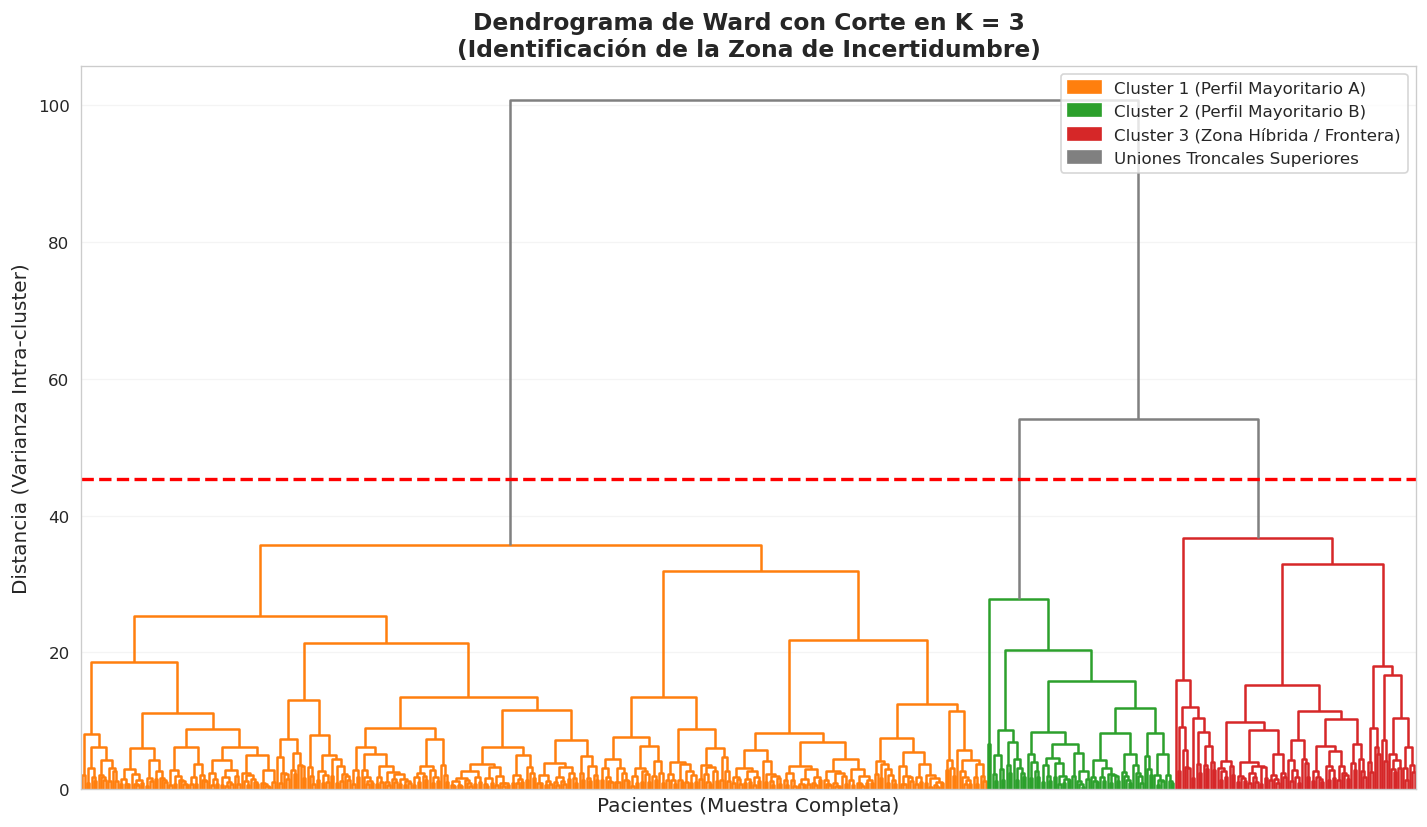

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Calculamos el enlace de Ward (si no lo tenías guardado)
Z_ward = linkage(scores5, method='ward')

# 2. Encontrar la distancia de corte automática para K=3
# Z_ward[-2, 2] nos da la distancia de la penúltima unión (donde se forman 3 grupos)
# Multiplicamos por un factor intermedio para asegurar que el corte caiga en el hueco correcto
distancia_corte = (Z_ward[-2, 2] + Z_ward[-3, 2]) / 2

fig, ax = plt.subplots(figsize=(12, 7))

# 3. Graficar el dendrograma con el umbral para 3 grupos
dend = dendrogram(
    Z_ward,
    ax=ax,
    no_labels=True,  # Oculta los IDs de los pacientes para mantener limpio el gráfico
    color_threshold=distancia_corte,  # Colorea según el corte K=3
    above_threshold_color='gray'      # Las uniones superiores quedan en gris
)

# 4. Dibujar la línea horizontal que representa el "tajo" del cirujano/analista
ax.axhline(y=distancia_corte, color='red', linestyle='--', lw=2, 
           label=f'Línea de corte (Distancia ≈ {distancia_corte:.1f})')

# 5. Configuración estética y títulos
ax.set_title('Dendrograma de Ward con Corte en K = 3\n(Identificación de la Zona de Incertidumbre)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Pacientes (Muestra Completa)', fontsize=12)
ax.set_ylabel('Distancia (Varianza Intra-cluster)', fontsize=12)
ax.grid(axis='y', alpha=0.2)

# Obtener los colores únicos que usó SciPy para la leyenda de los clusters
colores_ramas = list(set(dend['color_list']))
if 'gray' in colores_ramas: colores_ramas.remove('gray')

# Crear leyenda manual para los 3 clusters identificados por el algoritmo
parches = [
    mpatches.Patch(color=colores_ramas[0], label='Cluster 1 (Perfil Mayoritario A)'),
    mpatches.Patch(color=colores_ramas[1], label='Cluster 2 (Perfil Mayoritario B)'),
    mpatches.Patch(color=colores_ramas[2], label='Cluster 3 (Zona Híbrida / Frontera)'),
    mpatches.Patch(color='gray', label='Uniones Troncales Superiores')
]
ax.legend(handles=parches, loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

Cluster C (¡El nuevo grupo!): Aquí está la magia. Aparece un tercer cluster híbrido o mixto, donde conviven una porción de tumores malignos de menor tamaño junto con aquellos tumores benignos que eran inusualmente grandes o inflamatorios.

Si un patólogo utiliza tu modelo de 3 clusters, sabe exactamente qué hacer: el Cluster C es el que no se puede automatizar.Mientras que los pacientes del Cluster A van a su casa y los del Cluster B van a quirófano, el Cluster C es la bandeja de casos que exige obligatoriamente una junta médica.
Al forzar $K=3$, el algoritmo de Ward demostró una tremenda sensibilidad clínica: aisló el "área gris" de la medicina en su propia caja para que ningún médico la pase por alto


## 6. DBSCAN

DBSCAN en Wisconsin es un caso interesante: los datos tienen una estructura
bastante compacta y separada, pero con algunos casos borderline.
Exploramos cómo eps afecta los resultados.

DBSCAN cambia por completo la filosofía de los algoritmos anteriores. Mientras que K-Means busca "esferas" y el Jerárquico busca "árboles", DBSCAN busca densidad y continuidad

 DBSCAN no te pregunta cuántos grupos quieres; en su lugar, camina por la plaza usando dos reglas (sus dos hiperparámetros sagrados):
 eps ($\epsilon$ - Épsilon): Es el radio de tu "barrio". Define qué tan cerca tiene que estar un paciente de otro para considerarse su vecino directo.
 min_samples: Es el número mínimo de vecinos que exige el algoritmo para considerar que una zona está "densamente poblada" y formar un grupo.

 DBSCAN clasifica automáticamente a cada paciente en una de estas tres categorías:

A. Puntos Núcleo (Core Points)
Son los pacientes que están en el "corazón" de la enfermedad. Cumplen con la condición de que, si dibujas un círculo de radio eps a su alrededor, tienen al menos el número de vecinos exigido por min_samples.

B. Puntos Frontera (Border Points)
Son pacientes que no tienen suficientes vecinos a su alrededor para ser un "Punto Núcleo", pero caen dentro del barrio de un Punto Núcleo. Representan los casos límite o de transición.

C. Ruido / Atípicos (Noise Points) ¡Esta es la genialidad de DBSCAN! Si un paciente no es un Punto Núcleo y tampoco tiene a ningún Punto Núcleo cerca en su radio eps, el algoritmo lo descarta por completo y lo etiqueta como -1 (Ruido).  Son los outliers médicos puros.

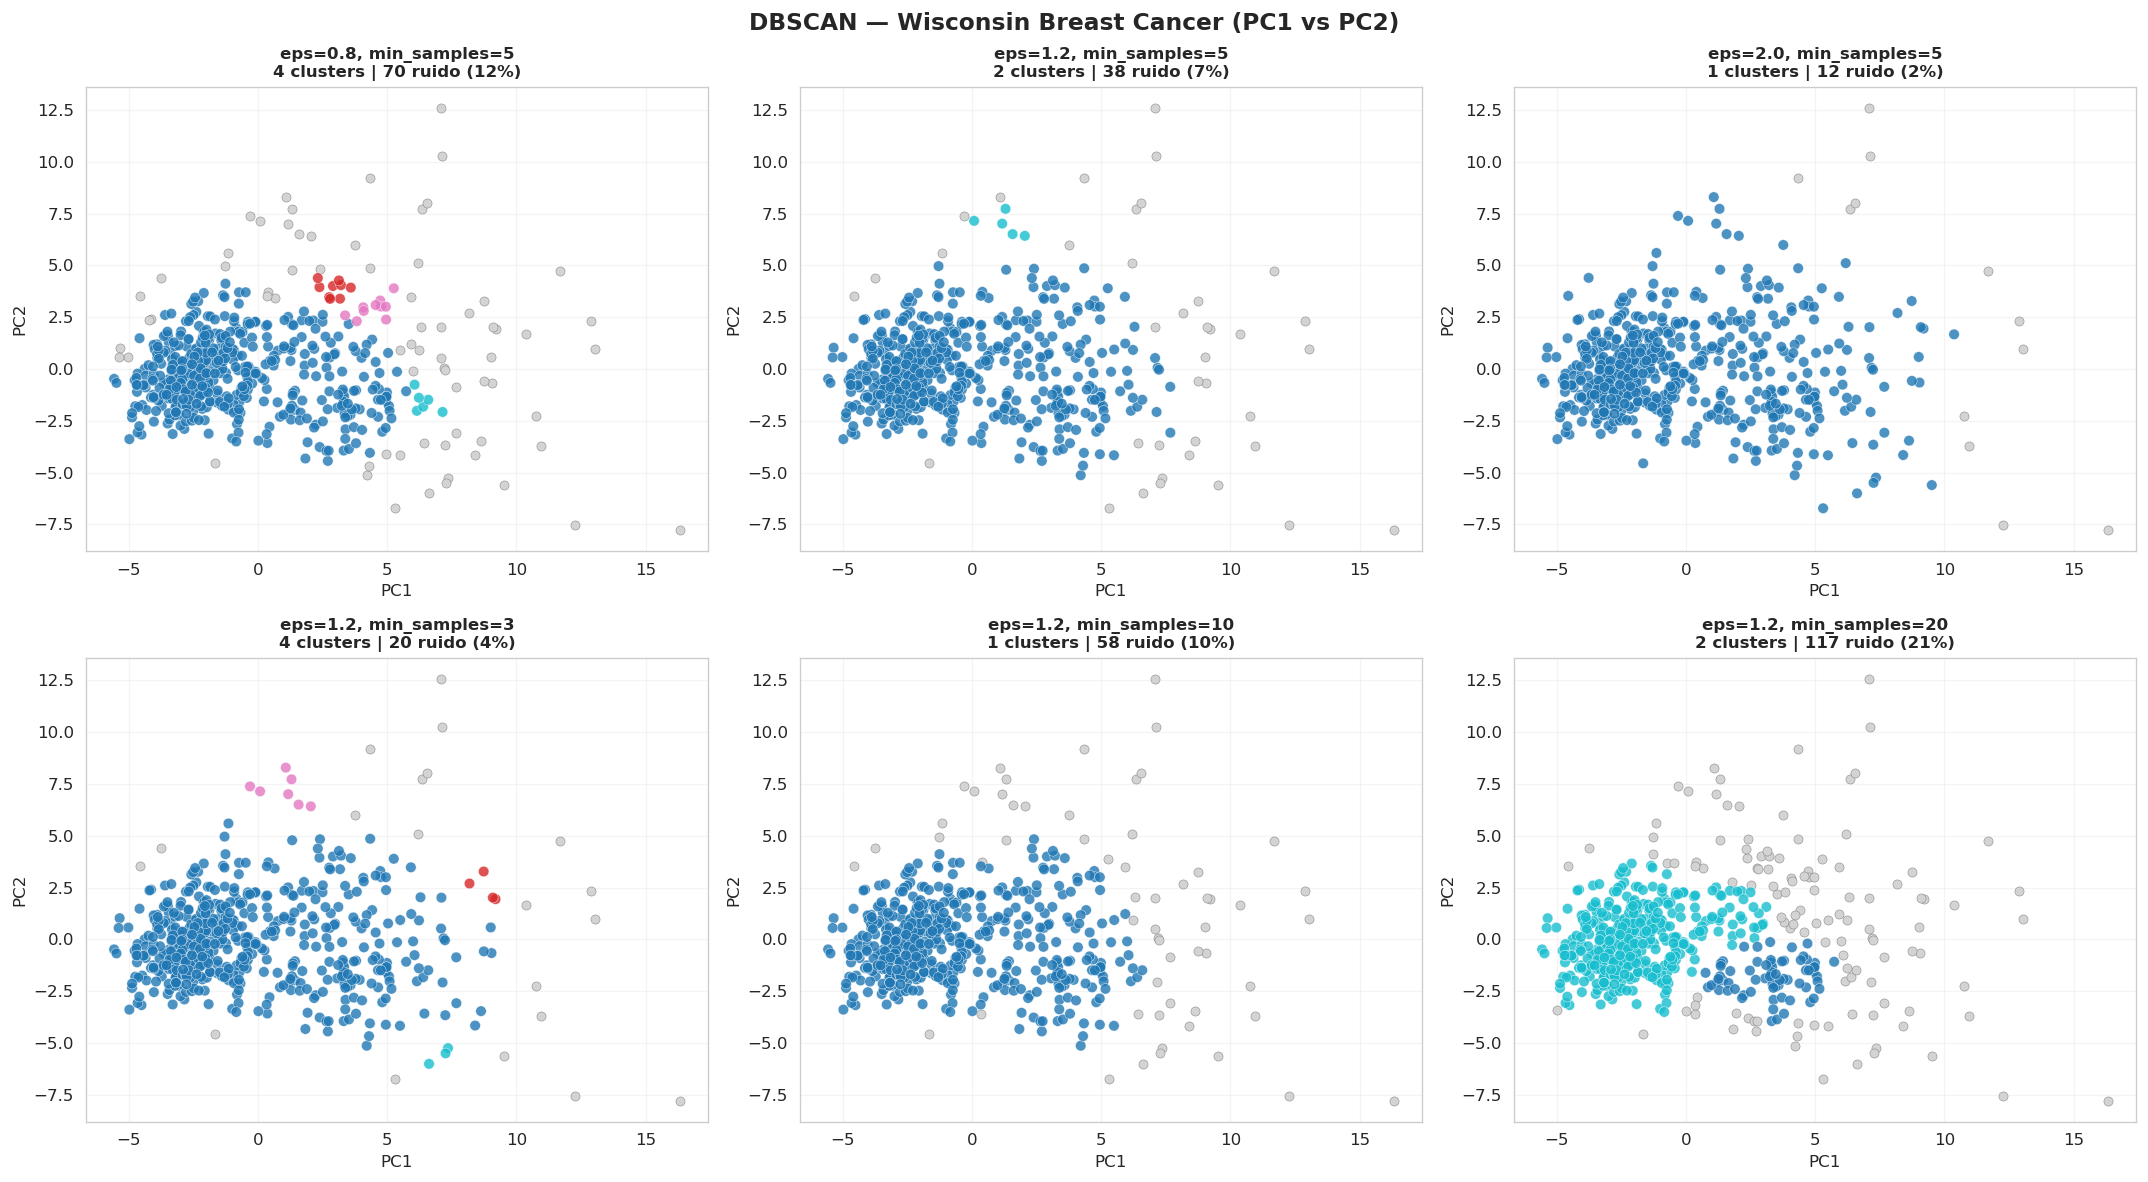

In [23]:
# Usamos las 2 primeras CPs para visualización clara
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('DBSCAN — Wisconsin Breast Cancer (PC1 vs PC2)',
             fontsize=14, fontweight='bold')

configs = [(0.8, 5), (1.2, 5), (2.0, 5), (1.2, 3), (1.2, 10), (1.2, 20)]

for ax, (eps_val, min_s) in zip(axes.flatten(), configs):
    db = DBSCAN(eps=eps_val, min_samples=min_s)
    db_labels = db.fit_predict(scores2)

    n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    n_ruido = (db_labels == -1).sum()

    # Puntos de ruido en gris
    ruido_mask = db_labels == -1
    ax.scatter(scores2[ruido_mask, 0], scores2[ruido_mask, 1],
               c='lightgray', s=30, label='Ruido', zorder=2, edgecolors='gray', linewidth=0.3)
    if n_clusters > 0:
        no_ruido = ~ruido_mask
        scatter = ax.scatter(scores2[no_ruido, 0], scores2[no_ruido, 1],
                             c=db_labels[no_ruido], cmap='tab10',
                             s=40, alpha=0.8, zorder=3,
                             edgecolors='white', linewidth=0.3)

    ax.set_title(f'eps={eps_val}, min_samples={min_s}\n{n_clusters} clusters | {n_ruido} ruido ({n_ruido/len(y)*100:.0f}%)',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Todos los pacientes que el algoritmo considera outliers o inclasificables se pintan de un color gris tenue.
Si el algoritmo logró fundar al menos un grupo estable, toma a los pacientes que NO son ruido (~ruido_mask) y los pinta usando una paleta de colores indexada (cmap='tab10'). Cada color representará un cluster diferente descubierto.


### 💬 Preguntas disparadoras — DBSCAN

1. ¿Qué combinación de eps y min_samples les parece más razonable? ¿Por qué?
2. Los puntos de ruido, ¿tienen alguna interpretación clínica interesante?
3. ¿En qué tipo de problemas de salud DBSCAN podría ser más útil que K-Means?
   Pista: pensá en detección de brotes epidémicos o patrones de uso de servicios de salud.

---

**✏️ Ejercicio 5:**
Usá la función `sklearn.neighbors.NearestNeighbors` para construir el gráfico k-distance
(distancia al k-ésimo vecino más cercano para cada punto, ordenada de mayor a menor).
El 'codo' de ese gráfico sugiere un buen valor de eps. ¿Qué eps obtenés?
¿Coincide con el que funcionó mejor visualmente?

El grupo de tumores benignos (a la izquierda) es hiper-denso y compacto, mientras que el grupo de tumores malignos (a la derecha) está mucho más disperso y esparcido.

1. De las 6 configuraciones, la que encontro 2 clusters principales y dejó un 7% de ruido (38 puntos grises). Capturó perfectamente la masa benigna (azul oscuro a la izquierda) y logró agrupar la parte más densa de la masa maligna (el pequeño grupo de puntos cian arriba, y el azul claro intermedio). Los puntos grises dispersos a la extrema derecha son los tumores malignos más gigantes y atípicos; DBSCAN prefiere decir "son ruido" antes que deformar los grupos principales.

2. Los puntos de ruido, outliers en terminos estadisticos, son casos con gran tamaño y agresividad. En la medicina oncológica, los puntos de ruido de DBSCAN son, irónicamente, los pacientes más importantes del hospital.

3. DBSCAN destruye por completo a K-Means en problemas de salud pública donde el espacio de análisis no es una tabla abstracta de variables clínicas, sino el espacio geográfico real (coordenadas GPS de latitud y longitud) o el tiempo continuo. Es decir, cuando agregamos informacion geografica o espacial, o temporal, donde la vecindad de los datos esta sujeta a esa informacion, el algoritmo DBSCAN se hace mas eficiente y no altera el mapa de valores. 

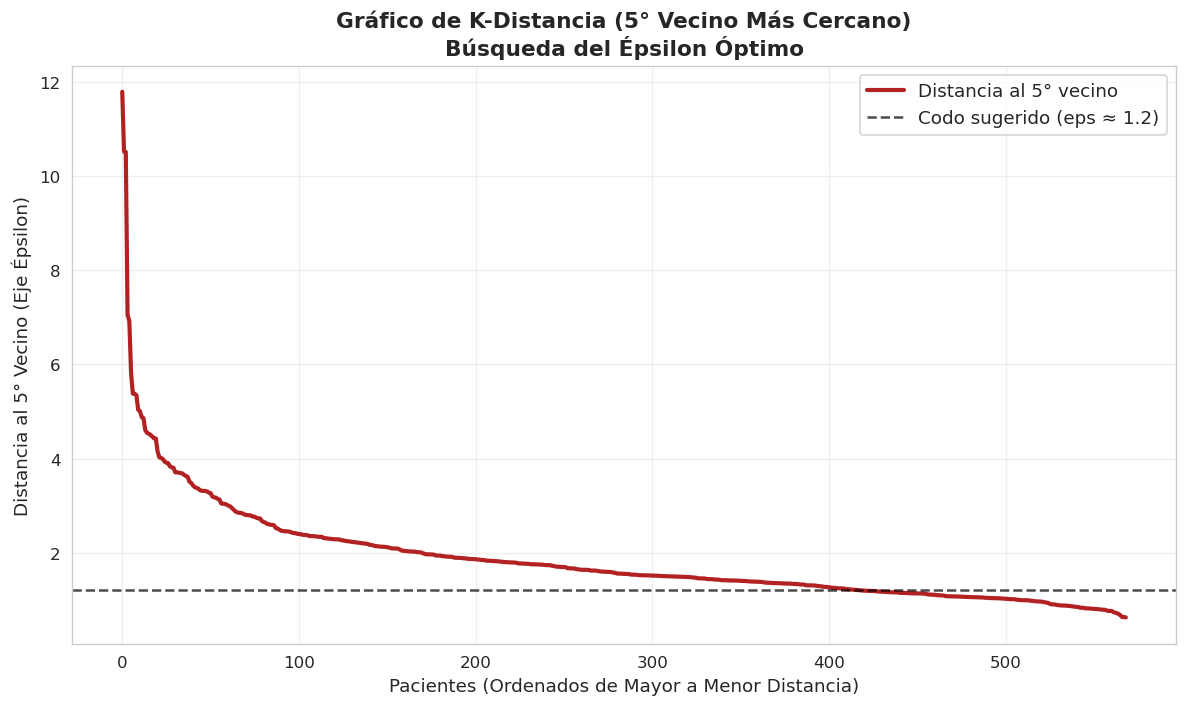

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# 1. Definimos el valor de k basado en el min_samples que elegimos antes (ej. min_samples = 5)
# Usamos k = 5 para medir la distancia al 5° vecino más cercano de cada paciente
k_vecinos = 5

# 2. Entrenamos el modelo de vecinos más cercanos
# El algoritmo calcula la matriz de distancias en el espacio de 5 CPs
nn = NearestNeighbors(n_neighbors=k_vecinos)
nn.fit(scores5)

# 3. Extraemos las distancias y los índices correspondientes
# distances tiene forma (n_pacientes, k_vecinos)
distances, _ = nn.kneighbors(scores5)

# 4. Tomamos la distancia al K-ésimo vecino (la última columna, índice k_vecinos-1)
# Y la ordenamos de MAYOR a MENOR (descendente) como solicitaste
k_distances = distances[:, k_vecinos - 1]
k_distances_sorted = np.sort(k_distances)[::-1]  # [::-1] invierte el array para orden descendente

# 5. Graficar el método de la rodilla / codo de K-Distancia
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(k_distances_sorted, color='firebrick', lw=2.5, label='Distancia al 5° vecino')

# Estimación visual del codo basado en tus experimentos previos
# Si recuerdas, eps=1.2 funcionaba muy bien; aquí deberías ver la curva estabilizarse cerca de ese valor
eps_sugerido = 1.2 
ax.axhline(y=eps_sugerido, color='black', linestyle='--', alpha=0.7, 
           label=f'Codo sugerido (eps ≈ {eps_sugerido})')

# Personalización estética
ax.set_title(f'Gráfico de K-Distancia ({k_vecinos}° Vecino Más Cercano)\nBúsqueda del Épsilon Óptimo', 
             fontsize=13, fontweight='bold')
ax.set_xlabel('Pacientes (Ordenados de Mayor a Menor Distancia)', fontsize=11)
ax.set_ylabel(f'Distancia al {k_vecinos}° Vecino (Eje Épsilon)', fontsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

## 7. Comparación de Métricas y Conclusiones

Comparamos todos los métodos con las tres métricas principales.

In [24]:
# Recopilar todos los resultados
todos = [
    ('K-Means K=2',            labels_km),
    ('Jerarquico Complete K=2', resultados_h['Complete'][0]),
    ('Jerarquico Average K=2',  resultados_h['Average'][0]),
    ('Jerarquico Ward K=2',     resultados_h['Ward'][0]),
]

# Agregar DBSCAN con eps=1.2, min_samples=5
db_final = DBSCAN(eps=1.2, min_samples=5).fit_predict(scores2)
n_ruido_final = (db_final == -1).sum()
if len(set(db_final)) - (1 if -1 in db_final else 0) >= 2:
    todos.append(('DBSCAN eps=1.2', db_final))

print(f'{'Metodo':<28} {'ARI':>8} {'Silhouette':>12} {'Davies-Bouldin':>16} {'% correcto':>12}')
print('-' * 80)

resumen = []
for nombre, lp in todos:
    mask_validos = lp != -1     # DBSCAN puede tener ruido
    y_val = y[mask_validos]
    lp_val = lp[mask_validos]
    if len(set(lp_val)) < 2:
        print(f'{nombre:<28}  (no suficientes clusters para calcular métricas)')
        continue
    ari = adjusted_rand_score(y_val, lp_val)
    sil = silhouette_score(scores5[mask_validos], lp_val)
    db  = davies_bouldin_score(scores5[mask_validos], lp_val)
    cm1 = confusion_matrix(y_val, lp_val)
    cm2 = confusion_matrix(y_val, 1 - np.clip(lp_val, 0, 1))
    cm  = cm1 if cm1.diagonal().sum() >= cm2.diagonal().sum() else cm2
    pct = cm.diagonal().sum() / len(y_val) * 100
    resumen.append((nombre, ari, sil, db, pct))
    print(f'{nombre:<28} {ari:8.3f} {sil:12.3f} {db:16.3f} {pct:11.1f}%')

Metodo                            ARI   Silhouette   Davies-Bouldin   % correcto
--------------------------------------------------------------------------------
K-Means K=2                     0.671        0.393            1.141        91.0%
Jerarquico Complete K=2         0.005        0.666            0.412        63.1%
Jerarquico Average K=2          0.005        0.666            0.412        63.1%
Jerarquico Ward K=2             0.538        0.377            1.224        86.8%
DBSCAN eps=1.2                 -0.009        0.382            0.921        64.8%


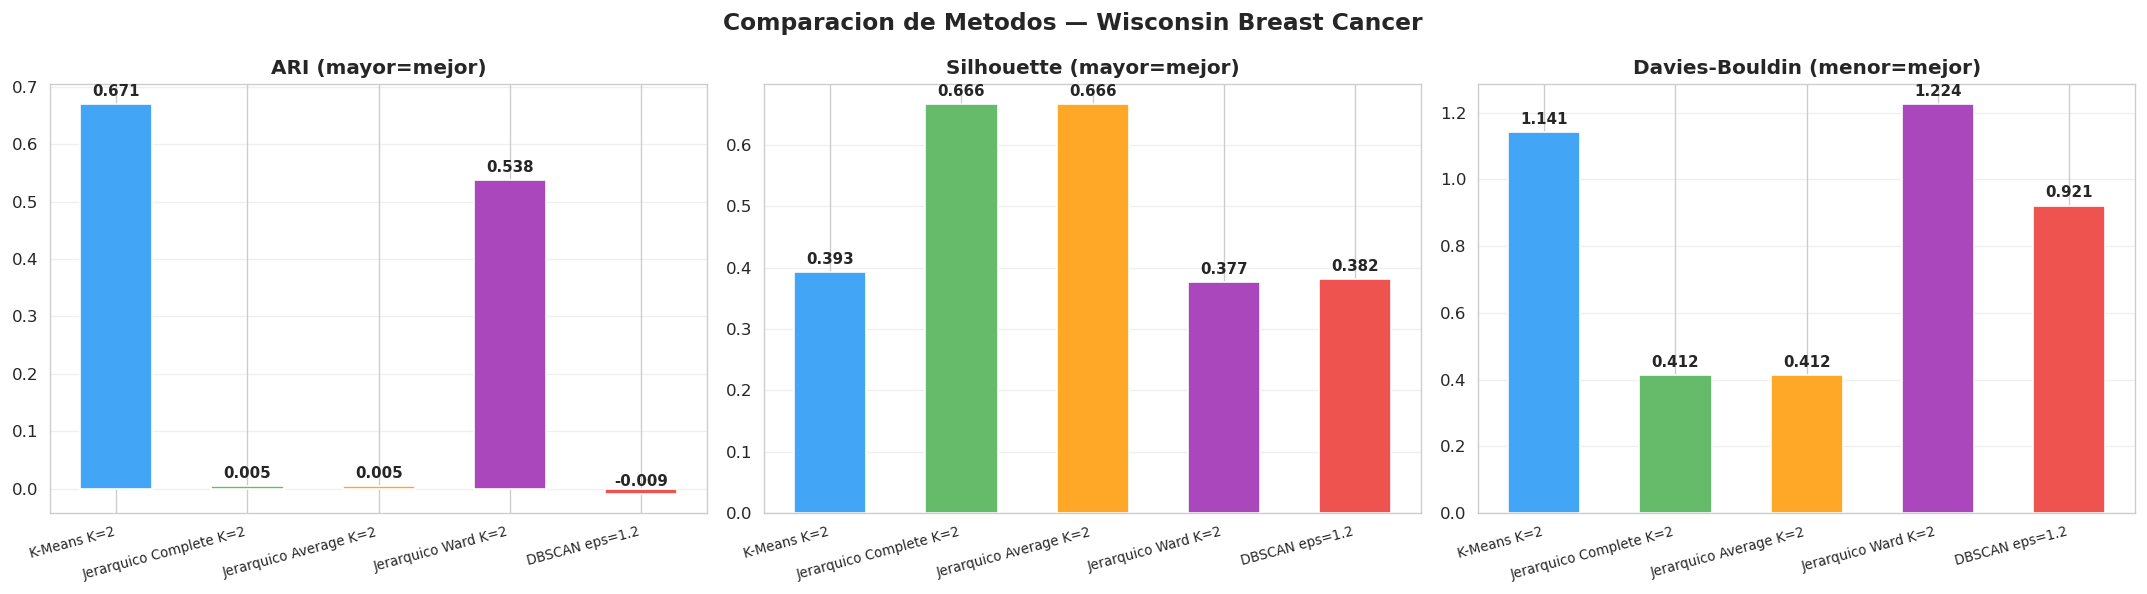

In [26]:
# Gráfico comparativo de métricas
if resumen:
    nombres_r  = [r[0] for r in resumen]
    ari_r      = [r[1] for r in resumen]
    sil_r      = [r[2] for r in resumen]
    db_r       = [r[3] for r in resumen]
    pct_r      = [r[4] for r in resumen]

    colores_b = ['#42A5F5', '#66BB6A', '#FFA726', '#AB47BC', '#EF5350']
    x = np.arange(len(nombres_r))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Comparacion de Metodos — Wisconsin Breast Cancer',
                 fontsize=14, fontweight='bold')

    for ax, vals, titulo in zip(axes,
                                 [ari_r, sil_r, db_r],
                                 ['ARI (mayor=mejor)', 'Silhouette (mayor=mejor)',
                                  'Davies-Bouldin (menor=mejor)']):
        bars = ax.bar(x, vals, color=colores_b[:len(nombres_r)],
                      edgecolor='white', width=0.55)
        ax.set_xticks(x)
        ax.set_xticklabels(nombres_r, fontsize=8, rotation=15, ha='right')
        ax.set_title(titulo, fontweight='bold')
        ax.grid(axis='y', alpha=0.3)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + max(vals)*0.02,
                    f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

> ### 📌 Nota para el docente — Lectura final de métricas
> **Ward y K-Means** suelen ser los mejores métodos para este dataset,
> con ARI ~0.5–0.6 y ~85–90% de casos correctamente agrupados.
>
> **Reflexión importante para cerrar la clase:**
> Un ARI de 0.55 sobre un problema de 2 clases significa que el algoritmo,
> *sin ver ninguna etiqueta*, recupera gran parte de la estructura real.
> Esto es notable — y también ilustra el límite del aprendizaje no supervisado.
>
> **Comparación con NCI60:**
> | | NCI60 | Wisconsin BC |
> |---|---|---|
> | Grupos reales | 14 | 2 |
> | Mejor ARI | ~0.35 | ~0.55–0.60 |
> | Separación en PCA | Parcial | Clara |
>
> La diferencia refleja la complejidad del problema, no la calidad del algoritmo.
>
> **Cierre conceptual:**
> El aprendizaje no supervisado es más útil cuando *no tenemos etiquetas*.
> Cuando sí las tenemos (como acá), es una herramienta de *validación* y *exploración*,
> no de clasificación. Para clasificar con etiquetas conocidas → aprendizaje supervisado.

### 💬 Preguntas de cierre — Para reflexionar

1. Si tuviesen que elegir **un solo método** para implementar en un sistema de apoyo diagnóstico,
   ¿cuál elegirían? Justificá considerando precisión, interpretabilidad y recursos.

2. ¿Qué información adicional (que no está en este dataset) les gustaría tener
   para mejorar el modelo?

3. Ahora que vieron NCI60 y Wisconsin: ¿en qué tipo de problema de salud real
   usarían cada dataset como analogía? ¿Cuándo preferirían un enfoque supervisado?

---

**✏️ Ejercicio final integrador:**

El dataset tiene variables `_mean`, `_se` y `_worst`. Hasta ahora usamos todas.
Repetí el análisis usando **solo las variables `_worst`** (las más extremas).

a) ¿Cambian los resultados del clustering?  
b) ¿Cambia la varianza explicada por PC1?  
c) ¿Tiene sentido clínico usar solo los valores extremos?

---

## Resumen del Lab

| Paso | ¿Qué hicimos? | ¿Para qué sirve? |
|---|---|---|
| EDA | Boxplots, correlaciones, descriptivos | Entender el problema antes de modelar |
| Estandarización | StandardScaler | Poner todas las variables en la misma escala |
| PCA | Reducir 30 → 5 dimensiones | Eliminar redundancia, facilitar clustering |
| K-Means | Dos clusters sobre CPs | Separación rápida, interpretable |
| Jerárquico | Dendrograma + Ward | Ver estructura sin asumir K |
| DBSCAN | Detección basada en densidad | Identificar outliers y formas no esféricas |
| Métricas | ARI, Silhouette, Davies-Bouldin | Comparar métodos objetivamente |